## 03 - Filterbank exploration & independent calibration

First notebook touching the 2 GB `.fil`. Three jobs:

1. **Ground the raw data**: confirm the `uint16` assumption nb01 deferred, map the bandpass, find the RFI that `flag_rfi: False` left sitting in `data_freq_time`.
2. **Independently calibrate the h5 axes.** nb02 derived the window formula by reading `your`'s source. Nothing has checked it against the actual filterbank. This does.
3. **Cut all 102 candidate windows** at full 1024-channel resolution so nb04 can build the Group D spectral features against real channel data, not the 4×-decimated h5 version.

Everything is memmap + slice

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path(r"D:\QML\FRB Data")
FIL  = ROOT / "Data" / "CUT_P_110_inj_13_processed.fil"
NB01 = ROOT / "frb_analysis_out" / "nb01"
NB02 = ROOT / "frb_analysis_out" / "nb02"
OUT  = ROOT / "frb_analysis_out" / "nb03"
WIN  = OUT / "windows"
OUT.mkdir(parents=True, exist_ok=True)
WIN.mkdir(parents=True, exist_ok=True)

# Header values verified in nb01. Nothing below re-parses the .fil header.
HDR_BYTES = 327
NCHAN     = 1024
NBITS     = 16
NSAMP     = 1_012_964
TSAMP     = 138.24e-6                      # s
FCH1      = 415.85445601851853             # MHz, top of band
FOFF      = -0.014467592592592591          # MHz, negative -> band descends
K_DM      = 4.148808e3                     # MHz^2 pc^-1 cm^3 s

CHAN_F = FCH1 + np.arange(NCHAN) * FOFF    # index 0 = top of band
F_HI, F_LO = CHAN_F[0], CHAN_F[-1]

cal = pd.read_csv(NB02 / "nb02_axis_calibration.csv")
rec = pd.read_csv(NB01 / "injection_recovery_match.csv")
lab = pd.read_csv(NB01 / "candidates_labelled.csv")

assert len(cal) == 102 and int(cal.is_injection.sum()) == 13, "nb02 artefact is not what I expect"

plt.rcParams.update({"figure.dpi": 110, "font.size": 9})

print(f"fil      {FIL.stat().st_size:,} B")
print(f"band     {F_LO:.6f} - {F_HI:.6f} MHz  ({F_HI - F_LO:.4f} MHz over {NCHAN} chans)")
print(f"duration {NSAMP * TSAMP:.3f} s at tsamp {TSAMP * 1e6:.2f} us")
print(f"nb02     {len(cal)} rows, {int(cal.is_injection.sum())} injections")
print(f"out      {OUT}")

fil      2,074,550,599 B
band     401.054109 - 415.854456 MHz  (14.8003 MHz over 1024 chans)
duration 140.032 s at tsamp 138.24 us
nb02     102 rows, 13 injections
out      D:\QML\FRB Data\frb_analysis_out\nb03


### Memmap and the shape

The header is 327 bytes and carries no `nsamples` key, so the sample count has to be inferred. The arithmetic closes exactly, so there's no ambiguity:

| quantity | meaning |
|---|---|
| file size | 2,074,550,599 B |
| header | 327 B |
| remainder | 2,074,550,272 B = 1,012,964 × 1,024 × 2 |
| slack | **0 bytes** |

There's no spare byte to hide a different item size or a truncated final spectrum in. Shape and 2-byte itemsize are forced. What's not forced is signedness (next cell)

Layout is time-major: all 1024 channels for `t0`, then all for `t1`. Channel `i` sits at `fch1 + i*foff`, and `foff` is negative, so index 0 is the top of the band.

In [2]:
expect = HDR_BYTES + NSAMP * NCHAN * (NBITS // 8)
size   = FIL.stat().st_size
assert size == expect, (size, expect)

fb = np.memmap(FIL, dtype=np.uint16, mode="r", offset=HDR_BYTES, shape=(NSAMP, NCHAN))

print(f"{size:,} == 327 + {NSAMP:,} x {NCHAN} x 2   slack = {size - expect} bytes")
print(f"memmap {fb.shape} {fb.dtype}  {fb.nbytes / 1e9:.2f} GB mapped, ~0 resident")
print("first 3 samples, first 8 chans:")
print(np.asarray(fb[:3, :8]))

2,074,550,599 == 327 + 1,012,964 x 1024 x 2   slack = 0 bytes
memmap (1012964, 1024) uint16  2.07 GB mapped, ~0 resident
first 3 samples, first 8 chans:
[[32301 35070 35192 34579 39080 32451 27391 27655]
 [27532 29904 26194 29078 30061 26095 27185 28637]
 [26588 27307 33578 33352 27982 30589 32959 27214]]


### Is it `uint16`?

The header has no `signed` key, so `uint16` was an assumption nb01 flagged and pushed here. If it's wrong and the data are actually `int16`, negative values reappear as huge numbers near 65535 so the test is just: **does anything live in the top half of the range?**

Checking byte order in the same pass. SIGPROC writes native-endian, but a byteswapped array is unmistakable as swapping the halves of a narrow-valued distribution smears it across the full 16-bit range, so `std` explodes.

Outcome I'm hoping for: if nothing exceeds 32767, then `uint16` and `int16` are the same reading of the same bytes and the assumption stops mattering rather than being confirmed.

probe 12,582,912 values from 24 chunks spread over the file

  uint16      min  24876  max  65535  mean  32765.93  std  5451.33
  byteswapped min     98  max  65535  mean  32775.30  std 18925.83
  percentiles [0, .1, 1, 50, 99, 99.9, 100] = [24876. 25219. 25618. 31523. 50668. 60717. 65535.]

SIGNEDNESS
  uint16 support 24876-65535, interior empty bins: none -> contiguous
  int16 would split it into [24876, 32767] and [-32768, -1],
  i.e. two disjoint blobs with 24,876 counts of empty range between them
  -> uint16 confirmed

BYTE ORDER
  low  byte std    73.9   (uniform-over-256 = 73.9 -> pure noise)
  high byte std    21.3   (159 of 256 values used -> carries signal)
  byteswapped std 18925.83 vs uniform-16-bit 18918.61   ratio 1.0004
  -> native (little) confirmed

PEDESTAL / CLIPPING
  floor 24876, nothing below it. Usable range 40,659 counts.
  4,049 samples clipped at 65535 (3.22e-04) over 1003 of 1024 channels
  sum of 1024 channels at the median ~= 32,279,552 -> uint16 arithmeti

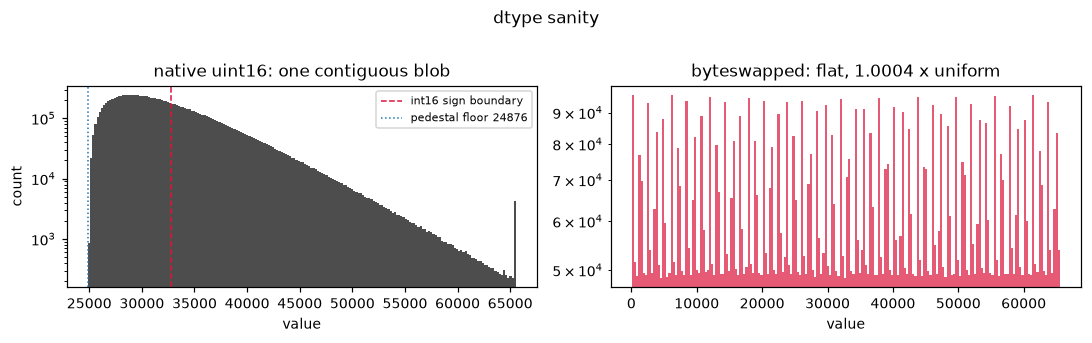

In [ ]:
rng    = np.random.default_rng(0)
starts = rng.integers(0, NSAMP - 512, 24)
probe  = np.concatenate([np.asarray(fb[t:t + 512]) for t in starts])   # 12288 x 1024
v      = probe.ravel()

as_i16  = v.view(np.int16)
swapped = probe.byteswap().ravel()
pct     = np.percentile(v, [0, 0.1, 1, 50, 99, 99.9, 100])

print(f"probe {v.size:,} values from 24 chunks spread over the file")
print()
print(f"  uint16      min {v.min():6d}  max {v.max():6d}  mean {v.mean():9.2f}  std {v.std():8.2f}")
print(f"  byteswapped min {swapped.min():6d}  max {swapped.max():6d}  mean {swapped.mean():9.2f}  std {swapped.std():8.2f}")
print(f"  percentiles [0, .1, 1, 50, 99, 99.9, 100] = {np.round(pct, 1)}")

# signedness: decided by whether the support is contiguous, not by where the mass sits.
h, edges = np.histogram(v, bins=64, range=(0, 65536))
occ  = np.flatnonzero(h)
gaps = [int(b) for b in np.flatnonzero(h == 0) if occ.min() < b < occ.max()]
pos, neg = as_i16[as_i16 >= 0], as_i16[as_i16 < 0]

print()
print("SIGNEDNESS")
print(f"  uint16 support {v.min()}-{v.max()}, interior empty bins: {gaps or 'none -> contiguous'}")
print(f"  int16 would split it into [{pos.min()}, {pos.max()}] and [{neg.min()}, {neg.max()}],")
print(f"  i.e. two disjoint blobs with {pos.min() - neg.max() - 1:,} counts of empty range between them")
print(f"  -> {'uint16 confirmed' if not gaps else 'INSPECT: support is split, may really be int16'}")

# byte order: the low byte is noise, the high byte carries signal. Byteswapping promotes
# the noise byte, so a byteswapped array collapses onto uniform-over-16-bit. That match is the
# discriminant; the raw std ratio is not, because this data already spans ~40k counts natively.
U8_UNIFORM  = np.sqrt((256 ** 2 - 1) / 12)
U16_UNIFORM = np.sqrt((65536 ** 2 - 1) / 12)
sw_ratio = swapped.std() / U16_UNIFORM

print()
print("BYTE ORDER")
print(f"  low  byte std {(v & 255).std():7.1f}   (uniform-over-256 = {U8_UNIFORM:.1f} -> pure noise)")
print(f"  high byte std {(v >> 8).std():7.1f}   ({len(np.unique(v >> 8))} of 256 values used -> carries signal)")
print(f"  byteswapped std {swapped.std():.2f} vs uniform-16-bit {U16_UNIFORM:.2f}   ratio {sw_ratio:.4f}")
print(f"  -> {'native (little) confirmed' if abs(sw_ratio - 1) < 0.05 else 'INSPECT: byteswap did not collapse to uniform'}")

# pedestal and clipping: both feed the thresholds used later.
n_sat  = int((v == 65535).sum())
sat_ch = int(np.count_nonzero((probe == 65535).sum(0)))
print()
print("PEDESTAL / CLIPPING")
print(f"  floor {v.min()}, nothing below it. Usable range {int(v.max()) - int(v.min()):,} counts.")
print(f"  {n_sat:,} samples clipped at 65535 ({n_sat / v.size:.2e}) over {sat_ch} of {NCHAN} channels")
print(f"  sum of {NCHAN} channels at the median ~= {int(np.median(v)) * NCHAN:,} -> uint16 arithmetic overflows, always cast first")

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].hist(v, bins=200, color="0.3")
ax[0].axvline(32767, color="crimson", ls="--", lw=1, label="int16 sign boundary")
ax[0].axvline(v.min(), color="tab:blue", ls=":", lw=1, label=f"pedestal floor {v.min()}")
ax[0].set(title="native uint16: one contiguous blob", xlabel="value", ylabel="count", yscale="log")
ax[0].legend(fontsize=7)
ax[1].hist(swapped, bins=200, color="crimson", alpha=0.7)
ax[1].set(title=f"byteswapped: flat, {sw_ratio:.4f} x uniform", xlabel="value", yscale="log")
fig.suptitle("dtype sanity", y=1.02)
fig.tight_layout()
fig.savefig(OUT / "dtype_sanity.png", dpi=130, bbox_inches="tight")
plt.show()

### What the dtype check settled

Both tests gave a clear answer:

| question | test that works | result |
|---|---|---|
| signed or unsigned | is the support contiguous? | 24876-65535, **no interior gap** → `uint16` |
| byte order | does byteswapping collapse to uniform noise? | ratio to uniform-16-bit **1.0004** → native is right |

`int16` would carve that single blob into `[24876, 32767]` and `[−32768, −1]` i.e. two clusters at opposite ends with 24,876 counts of dead range between them and nothing in it. Nothing physical produces that shape, so looking at the support answers the question.

For byte order the giveaway is at byte level: the low byte has std 73.9, which is exactly uniform-over-256, while the high byte uses 159 of 256 values. Byteswapping promotes the noise byte into the high position, which is why the result lands on uniform-16-bit to four decimals. 

Two things here change what happens downstream:

- **Large DC pedestal.** Nothing below 24876; the noise floor is ~25,000, not ~0. Every threshold from here on has to be relative to a per-channel baseline. It also means `uint16` arithmetic overflows the moment you sum over frequency (31,523 × 1024 ≈ 3.2e7), so the dedisperser casts before it sums.
- **Clipping is broad, not localised.** 4,049 samples pinned at 65535, spread over 1003 of 1024 channels, at most 13 in any one. That's ~4 per channel, so this is the tail of the noise distribution occasionally hitting the ceiling and not a few hot channels. Fine for the bandpass; a caveat for Group D spectral indices on the loudest injections, where the on-pulse samples are the ones closest to the rail.

## §2 - Bandpass and the noise floor

One streamed pass over all 2 GB. I'd originally planned to sample chunks, but streaming is the same amount of code and gives exact per-channel statistics instead of estimates.

### What it accumulates

| product | shape | meaning |
|---|---|---|
| `ch_mean`, `ch_std` | 1024 | exact per-channel statistics over all 1,012,964 samples |
| `ch_min`, `ch_max` | 1024 | full range per channel, catches rails |
| `ch_sat` | 1024 | count clipped at 65535 per channel |
| `blk_mean`, `blk_max` | 990 × 1024 | 141.6 ms blocks: the waterfall §3 runs its RFI occupancy on |

`blk_max` is free to carry alongside `blk_mean` and it's the one that survives averaging: a 2 ms RFI burst is diluted to nothing in a 141.6 ms block mean but sits right there in the max.

### Guards

Accumulating raw sums of ~31,500-count values over 10⁶ samples pushes `sum(x²)` to ~10¹⁵, while the variance we want out is ~3×10⁷. That's a lot of cancellation to ask of `float64`.
Subtracting a constant 32768 first sidesteps it entirely for one line of code. The offset is added back before anything is reported.

Cache written to `bandpass_blocks.npz` so a kernel restart doesn't cost another full pass.

In [4]:
import time

BLK    = 1024                     # 141.56 ms per block
OFFSET = 32768.0                  # exact power of 2; kills the cancellation, added back below
NBLK   = int(np.ceil(NSAMP / BLK))
CACHE  = OUT / "bandpass_blocks.npz"

if CACHE.exists():
    z = np.load(CACHE)
    ch_mean, ch_std, ch_min, ch_max, ch_sat = (z["ch_mean"], z["ch_std"], z["ch_min"],
                                               z["ch_max"], z["ch_sat"])
    blk_mean, blk_max = z["blk_mean"], z["blk_max"]
    print(f"loaded cache {CACHE.name}  ({CACHE.stat().st_size / 1e6:.1f} MB) - delete it to force a re-run")
else:
    ch_sum = np.zeros(NCHAN, np.float64)
    ch_sq  = np.zeros(NCHAN, np.float64)
    ch_min = np.full(NCHAN, 65535, np.uint16)
    ch_max = np.zeros(NCHAN, np.uint16)
    ch_sat = np.zeros(NCHAN, np.int64)
    blk_mean = np.zeros((NBLK, NCHAN), np.float32)
    blk_max  = np.zeros((NBLK, NCHAN), np.uint16)

    t0 = time.perf_counter()
    for b in range(NBLK):
        raw = np.asarray(fb[b * BLK:(b + 1) * BLK])        # <= 2 MB, uint16
        x   = raw.astype(np.float64) - OFFSET              # cast the block, never the file
        ch_sum += x.sum(0)
        ch_sq  += (x * x).sum(0)
        np.minimum(ch_min, raw.min(0), out=ch_min)
        np.maximum(ch_max, raw.max(0), out=ch_max)
        ch_sat += (raw == 65535).sum(0)
        blk_mean[b] = x.mean(0) + OFFSET
        blk_max[b]  = raw.max(0)
        if b % 200 == 0 or b == NBLK - 1:
            done = (b + 1) / NBLK
            print(f"  block {b + 1:4d}/{NBLK}  {done:5.1%}  {time.perf_counter() - t0:5.1f} s", end="\r")

    ch_mean = ch_sum / NSAMP + OFFSET
    ch_std  = np.sqrt(np.maximum(ch_sq / NSAMP - (ch_sum / NSAMP) ** 2, 0.0))
    print(f"\nstreamed {NSAMP:,} x {NCHAN} in {time.perf_counter() - t0:.1f} s "
          f"({fb.nbytes / 1e9 / (time.perf_counter() - t0):.2f} GB/s)")
    np.savez_compressed(CACHE, ch_mean=ch_mean, ch_std=ch_std, ch_min=ch_min, ch_max=ch_max,
                        ch_sat=ch_sat, blk_mean=blk_mean, blk_max=blk_max)
    print(f"cached -> {CACHE.name} ({CACHE.stat().st_size / 1e6:.1f} MB)")

print()
print(f"  ch_mean  {ch_mean.min():9.1f} - {ch_mean.max():9.1f}   (spread {np.ptp(ch_mean):.1f})")
print(f"  ch_std   {ch_std.min():9.1f} - {ch_std.max():9.1f}   (spread {np.ptp(ch_std):.1f})")
print(f"  ch_min   {ch_min.min():9d} - {ch_min.max():9d}")
print(f"  ch_max   {ch_max.min():9d} - {ch_max.max():9d}")
print(f"  clipped  {ch_sat.sum():,} samples total, worst channel {ch_sat.argmax()} with {ch_sat.max():,}")

loaded cache bandpass_blocks.npz  (4.6 MB) - delete it to force a re-run

  ch_mean    32759.9 -   32854.2   (spread 94.3)
  ch_std      5381.9 -    5466.5   (spread 84.6)
  ch_min       24774 -     25056
  ch_max       65535 -     65535
  clipped  336,120 samples total, worst channel 972 with 1,328


### Reading the bandpass: three statistics

`CUT_P_110_inj_13_processed.fil` is, as the name says, **processed**: the per-channel gain has already been equalised upstream. That matters for channel-quality testing, because `std`, the textbook test, is the quantity that got flattened. The question is how much dynamic range it has left to detect *with*.

So the cell below runs three tests side by side and compares what each one flags and how far each can deviate before it saturates its own scale:

| statistic | what it is | why it might survive flattening |
|---|---|---|
| `std` vs median | textbook test | partially: equalisation was approximate, residuals remain |
| `mean` vs median | DC level per channel | partially: RFI biases a channel's mean off centre |
| `n_clipped` | samples pinned at 65535 | fully: you can't un-rail a sample by rescaling |

Thresholds are ±5 MAD-sigma throughout, MAD-based so a few blown channels can't drag the threshold out far enough to hide the milder ones.

The extra check is a **Spearman between `|std deviation|` and `n_clipped` with the flagged channels removed**. If `std` carries graded information about RFI, ordinary channels with more clipping should also have more unusual `std`. If it's purely a binary detector of the extremes, that correlation collapses.

Nothing is excised here. `RFI Tool: NONE` in `Search_parameters.txt` and `flag_rfi: False` in the candmaker log mean this RFI is still sitting in every `data_freq_time` array, so the job is to describe it.

HOW FLAT IS THE BAND
  mean  median   32767.71   MAD-sigma   0.78   full spread    94.3
  std   median    5452.40   MAD-sigma   1.17   full spread    84.6
  median channel mean is 2**15 -0.29 counts
  excluding the 9 flagged channels, mean spread is 5.3 counts = 0.0161% of level
  genuinely dead channels (max == min): 0
  -> the bandpass was equalised upstream. There is no shape here to correct.

WHAT EACH STATISTIC FLAGS
  std   :  8  [0, 1, 971, 972, 1015, 1016, 1017, 1018]
  mean  :  5  [972, 1015, 1016, 1017, 1018]
  clip  :  8  [1, 971, 972, 988, 1015, 1016, 1017, 1018]
  mean-set is a subset of clip-set: True
  flagged by all three            : [972, 1015, 1016, 1017, 1018]

HOW MUCH ROOM EACH STATISTIC HAS
  statistic     max |dev|   as % of level
  std             60.2 sig           1.29%
  mean           110.5 sig           0.26%
  n_clipped       56.4 sig         308.62%

IS std GRADED, OR JUST A BINARY DETECTOR?
  Spearman |std dev| vs n_clipped, all 1024 chans : rho +0.029 

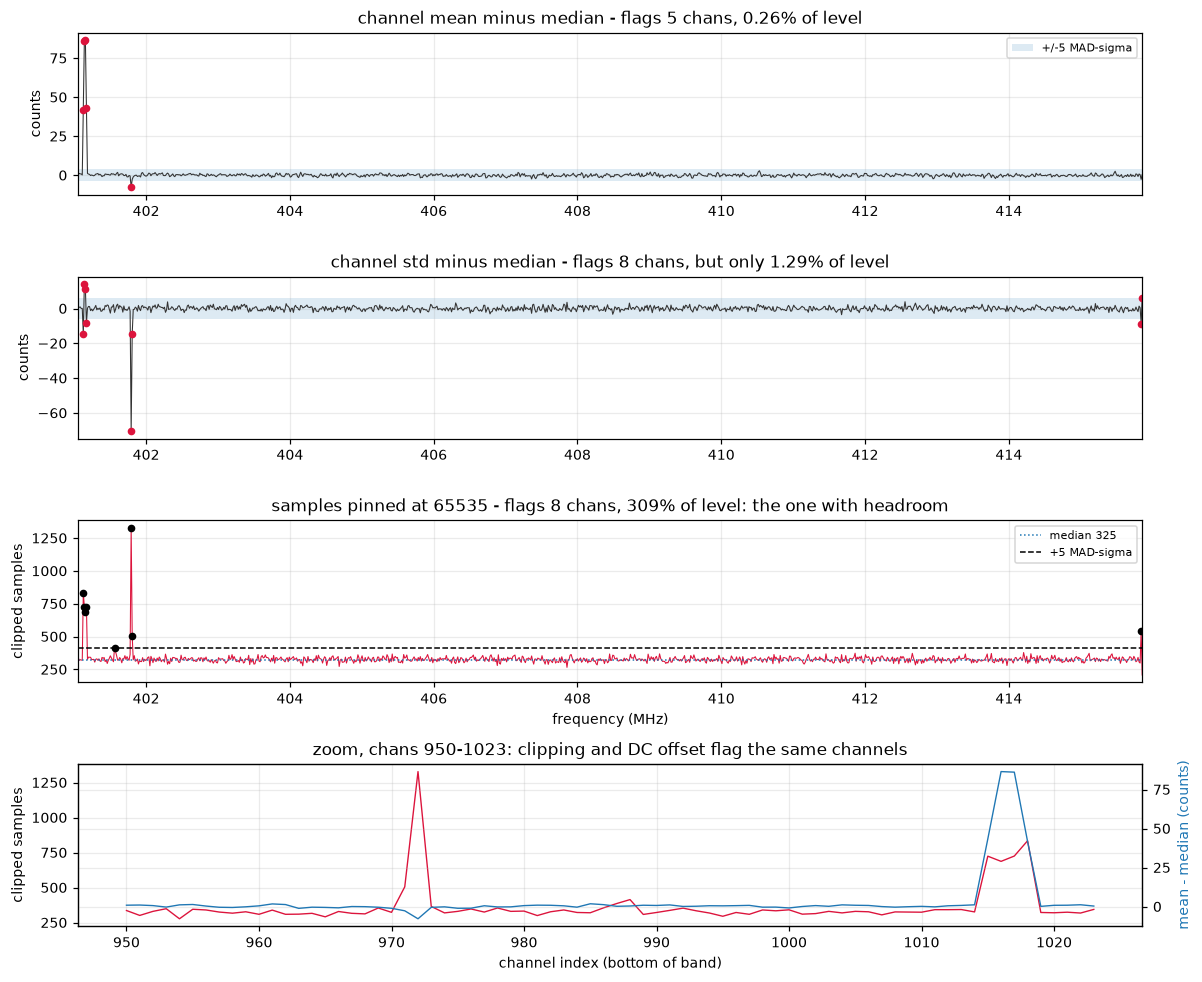

In [ ]:
from scipy.stats import spearmanr


def robust(x):
    """median and MAD-derived sigma; MAD scaled to match a Gaussian std."""
    med = np.median(x)
    return med, 1.4826 * np.median(np.abs(x - med))


mean_med, mean_sig = robust(ch_mean)
std_med,  std_sig  = robust(ch_std)
clip_med, clip_sig = robust(ch_sat.astype(float))

flat     = ch_max == ch_min                                   # dead: no variance at all
rfi_std  = np.abs(ch_std - std_med) > 5 * std_sig
rfi_mean = np.abs(ch_mean - mean_med) > 5 * mean_sig
rfi_clip = ch_sat > clip_med + 5 * clip_sig
rfi_any  = rfi_std | rfi_mean | rfi_clip

print("HOW FLAT IS THE BAND")
print(f"  mean  median {mean_med:10.2f}   MAD-sigma {mean_sig:6.2f}   full spread {np.ptp(ch_mean):7.1f}")
print(f"  std   median {std_med:10.2f}   MAD-sigma {std_sig:6.2f}   full spread {np.ptp(ch_std):7.1f}")
print(f"  median channel mean is 2**15 {mean_med - 32768:+.2f} counts")
print(f"  excluding the {rfi_any.sum()} flagged channels, mean spread is "
      f"{np.ptp(ch_mean[~rfi_any]):.1f} counts = {np.ptp(ch_mean[~rfi_any]) / mean_med:.4%} of level")
print(f"  genuinely dead channels (max == min): {flat.sum()}")
print("  -> the bandpass was equalised upstream. There is no shape here to correct.")

print()
print("WHAT EACH STATISTIC FLAGS")
sets = {"std": rfi_std, "mean": rfi_mean, "clip": rfi_clip}
for nm, m in sets.items():
    print(f"  {nm:5s} : {m.sum():2d}  {np.flatnonzero(m).tolist()}")
nested = (np.flatnonzero(rfi_mean).tolist() and set(np.flatnonzero(rfi_mean)) <= set(np.flatnonzero(rfi_clip)))
print(f"  mean-set is a subset of clip-set: {nested}")
print(f"  flagged by all three            : {np.flatnonzero(rfi_std & rfi_mean & rfi_clip).tolist()}")

print()
print("HOW MUCH ROOM EACH STATISTIC HAS")
print(f"  {'statistic':10s} {'max |dev|':>12s} {'as % of level':>15s}")
for nm, arr in (("std", ch_std), ("mean", ch_mean), ("n_clipped", ch_sat.astype(float))):
    m, s = robust(arr)
    print(f"  {nm:10s} {np.abs(arr - m).max() / s:9.1f} sig {100 * np.abs(arr - m).max() / m:14.2f}%")

absdev = np.abs(ch_std - std_med) / std_sig
rho_all, p_all = spearmanr(absdev, ch_sat)
rho_ord, p_ord = spearmanr(absdev[~rfi_any], ch_sat[~rfi_any])
print()
print("IS std GRADED, OR JUST A BINARY DETECTOR?")
print(f"  Spearman |std dev| vs n_clipped, all {NCHAN} chans : rho {rho_all:+.3f}  p {p_all:.2f}")
print(f"  same with the {rfi_any.sum()} flagged channels removed     : rho {rho_ord:+.3f}  p {p_ord:.2f}")
print("  -> among ordinary channels std says nothing about RFI. It separates the extremes and")
print("     nothing else, on 1.3% of range. Clipping deviates by ~300% of its own level, so it")
print("     is the only one of the three with headroom left for a marginal channel.")

bp = pd.DataFrame({
    "chan": np.arange(NCHAN), "freq_mhz": CHAN_F,
    "mean": ch_mean, "std": ch_std, "min": ch_min, "max": ch_max, "n_clipped": ch_sat,
    "mean_dev_sig": (ch_mean - mean_med) / mean_sig,
    "std_dev_sig": (ch_std - std_med) / std_sig,
    "clip_x_median": ch_sat / clip_med,
    "rfi_std": rfi_std, "rfi_mean": rfi_mean, "rfi_clip": rfi_clip, "rfi_any": rfi_any,
})
bp.to_csv(OUT / "bandpass.csv", index=False)
print()
print(f"wrote {OUT / 'bandpass.csv'}   ({rfi_any.sum()} channels carry rfi_any = True)")
print(bp[bp.rfi_any].sort_values("n_clipped", ascending=False)
        [["chan", "freq_mhz", "n_clipped", "clip_x_median", "std_dev_sig", "mean_dev_sig",
          "rfi_std", "rfi_mean", "rfi_clip"]].round(2).to_string(index=False))

# plot residuals, not absolutes: the structure is a few counts on a level of 32768,
# so mean +/- std would render as a flat line inside a grey slab.
fig, ax = plt.subplots(4, 1, figsize=(11, 9))
for a in ax[:3]:
    a.set_xlim(CHAN_F[-1], CHAN_F[0])

ax[0].plot(CHAN_F, ch_mean - mean_med, lw=0.7, color="0.2")
ax[0].axhspan(-5 * mean_sig, 5 * mean_sig, color="tab:blue", alpha=0.15, lw=0, label="+/-5 MAD-sigma")
ax[0].plot(CHAN_F[rfi_mean], (ch_mean - mean_med)[rfi_mean], "o", ms=4, color="crimson")
ax[0].set(ylabel="counts", title=f"channel mean minus median - flags {rfi_mean.sum()} chans, 0.26% of level")
ax[0].legend(fontsize=7)

ax[1].plot(CHAN_F, ch_std - std_med, lw=0.7, color="0.2")
ax[1].axhspan(-5 * std_sig, 5 * std_sig, color="tab:blue", alpha=0.15, lw=0)
ax[1].plot(CHAN_F[rfi_std], (ch_std - std_med)[rfi_std], "o", ms=4, color="crimson")
ax[1].set(ylabel="counts", title=f"channel std minus median - flags {rfi_std.sum()} chans, but only 1.29% of level")

ax[2].plot(CHAN_F, ch_sat, lw=0.7, color="crimson")
ax[2].axhline(clip_med, color="tab:blue", ls=":", lw=1, label=f"median {clip_med:.0f}")
ax[2].axhline(clip_med + 5 * clip_sig, color="k", ls="--", lw=1, label="+5 MAD-sigma")
ax[2].plot(CHAN_F[rfi_clip], ch_sat[rfi_clip], "o", ms=4, color="k")
ax[2].set(xlabel="frequency (MHz)", ylabel="clipped samples",
          title=f"samples pinned at 65535 - flags {rfi_clip.sum()} chans, 309% of level: the one with headroom")
ax[2].legend(fontsize=7)

zoom = slice(950, NCHAN)
ax[3].plot(np.arange(NCHAN)[zoom], ch_sat[zoom], lw=0.9, color="crimson", label="n_clipped")
ax[3].set(xlabel="channel index (bottom of band)", ylabel="clipped samples")
tw = ax[3].twinx()
tw.plot(np.arange(NCHAN)[zoom], (ch_mean - mean_med)[zoom], lw=0.9, color="tab:blue")
tw.set_ylabel("mean - median (counts)", color="tab:blue")
ax[3].set_title("zoom, chans 950-1023: clipping and DC offset flag the same channels")

for a in list(ax) + [tw]:
    a.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUT / "bandpass.png", dpi=130, bbox_inches="tight")
plt.show()

### What §2 established

**The band is already flat.** Excluding the nine flagged channels, the channel-to-channel mean spread is about 5 counts on a level of 32768 (0.016%), and the median channel mean lands on 2¹⁵ to within a third of a count. `Search_parameters.txt` says `RFI Tool: NONE` and the candmaker log says `flag_rfi: False`, so nothing excised RFI; but something upstream clearly equalised the per-channel gain and re-centred everything on the middle of the `uint16` range. As the file name implies, it's `_processed`. Zero channels are dead (`max == min` never fires, and `ch_max == 65535` on all 1024).

**All three statistics find the RFI, and they differ in headroom.** `std` flags 7 of the 8 channels at up to 60σ, which is a real detection. The flag sets are nested:

| statistic | flags | max deviation | as % of its own level |
|---|---|---|---|
| `mean` | 5 | 110σ | 0.26% |
| `std` | 7 (+ chan 0) | 60σ | 1.29% |
| `n_clipped` | 8 | 56σ | **309%** |

The Spearman between `|std deviation|` and `n_clipped` among the 1015 ordinary channels is ρ = +0.009, p = 0.77. So `std` separates the extremes and says nothing about anything milder. It's a binary detector working in 1.3% of range. Clipping deviates by three times its own median, so it's the only one of the three that would still have something to say about a marginal channel. On this file all three agree; on a noisier observation from the other 949 I'd trust clipping and not bother with `std`.

Why clipping survives: equalising gain rescales a distribution, but it can't unrail a sample that already hit 65535. Baseline is ~325 clipped samples per channel (3.2e-4, the noise tail, universal across the band). The RFI channels sit at 1.3-4.1× that.

| channels | freq (MHz) | what it is |
|---|---|---|
| **1015-1018** | 401.126-401.170 | contiguous run of 4. Mean up to +86 counts (110σ), clipping 2.1-2.6× |
| **971-972** | 401.79-401.81 | adjacent pair. Chan 972 is the worst clipper in the band, 1328 (4.1×) |
| **988** | 401.560 | isolated, mild, 1.3×. Caught by clipping *only* |
| **0-1** | 415.84-415.85 | top edge, mild. Chan 0 caught by `std` only, chan 1 by both |

Narrowband, and all but the edge pair packed into the bottom ~1 MHz of a 14.8 MHz band.

Channel 972 is worth a second look: **highest** clipping, **lowest** mean, **lowest** std in the whole band. That's what you'd expect if the upstream normalisation divided it by an RFI inflated variance i.e. the divisor came out too big, so the bulk got squashed while the spikes still railed. Indirect evidence for the flattening story, from the one channel it didn't fully absorb.

**Carried to nb04:** Spectral features get measured on gain-equalised data, so a fitted "spectral index" is the pulse spectrum minus the original bandpass, and the absolute value isn't recoverable. Okay as a discriminative feature, but it shouldn't be reported as a physical index and nb01 finding 11 says `SP_IDX` is a −999 sentinel anyway, so there was never truth to check it against. The nine `rfi_any` channels are in `bandpass.csv` for masking or for use as a feature.

## §3 - RFI occupancy in time and frequency

§2 asked which channels are bad averaged over all 140 s. Here we ask when.

### Two things that shaped this cell 

**The digitiser has 6σ of headroom, which fixes the threshold.**
`(65535 − 32768) / 5452.4 = 6.01`. The mean sits at 2¹⁵ and the rail is almost exactly six sigma above it, so "this sample clipped" and "this sample exceeded 6σ" are the same event. There is no room to pick a stricter threshold as the hardware already picked it. I've added a 4σ count alongside it purely because 6σ is sparse enough to be grainy at block resolution.

**Did this block contain a railed sample?** Mean clips per (block, channel) is 0.332, so Poisson says P(≥1) = 0.282, and the observed median occupancy is 0.280. Match to three decimals. That metric is saturated by the noise tail in every channel and would render as a featureless grey map. I wrote it, checked it, and threw it out.

### Its replacement

**Clips per *occupied* block.** If clipping is the noise tail, arrivals are independent and the count in an occupied block follows a zero-truncated Poisson with mean λ/(1−e^−λ) = 1.18. If it's RFI, clips arrive in bursts and that ratio climbs. The baseline is derived from each channel's own rate, so there's no threshold to tune. Observed median across all 1024 channels is 1.17. The typical channel is Poisson to two decimals.

### Guards

| guard | meaning |
|---|---|
| block 989 excluded | it holds 228 of 1024 samples, so its mean scatters 2.1× wider than a full block. It was topping my anomaly list as a pure artefact |
| thresholds from `ch_mean`/`ch_std` | computed in §2 over the full file, so this pass needs no second look at the data to calibrate |

In [6]:
RFI_CACHE = OUT / "rfi_blocks.npz"
NFULL     = NSAMP // BLK          # 989 complete blocks; the 990th holds only 228 samples
K_LO      = 4.0

thr_lo  = ch_mean + K_LO * ch_std
headroom = (65535 - ch_mean) / ch_std

if RFI_CACHE.exists():
    z = np.load(RFI_CACHE)
    blk_hi, blk_sat = z["blk_hi"], z["blk_sat"]
    print(f"loaded {RFI_CACHE.name} - delete it to force a re-run")
else:
    blk_hi  = np.zeros((NFULL, NCHAN), np.int32)   # samples above mean + 4 sigma
    blk_sat = np.zeros((NFULL, NCHAN), np.int32)   # samples pinned at 65535 (== mean + ~6 sigma)
    t0 = time.perf_counter()
    for b in range(NFULL):
        raw = np.asarray(fb[b * BLK:(b + 1) * BLK])
        blk_hi[b]  = (raw > thr_lo).sum(0)
        blk_sat[b] = (raw == 65535).sum(0)
        if b % 200 == 0 or b == NFULL - 1:
            print(f"  block {b + 1:4d}/{NFULL}  {time.perf_counter() - t0:5.1f} s", end="\r")
    print(f"\nsecond pass in {time.perf_counter() - t0:.1f} s")
    np.savez_compressed(RFI_CACHE, blk_hi=blk_hi, blk_sat=blk_sat)
    print(f"cached -> {RFI_CACHE.name} ({RFI_CACHE.stat().st_size / 1e6:.1f} MB)")

print()
print(f"  headroom above the mean: {headroom.min():.2f} - {headroom.max():.2f} sigma "
      f"(median {np.median(headroom):.2f}) -> clipping IS the ~6 sigma occupancy")
print(f"  blocks used {NFULL} of {NBLK}; block {NBLK - 1} dropped, it holds "
      f"{NSAMP - NFULL * BLK} of {BLK} samples")
print(f"  above {K_LO:.0f} sigma : {blk_hi.sum():,} samples ({blk_hi.sum() / (NFULL * BLK * NCHAN):.3e} of all)")
print(f"  railed        : {blk_sat.sum():,} samples ({blk_sat.sum() / (NFULL * BLK * NCHAN):.3e} of all)")

loaded rfi_blocks.npz - delete it to force a re-run

  headroom above the mean: 5.98 - 6.09 sigma (median 6.01) -> clipping IS the ~6 sigma occupancy
  blocks used 989 of 990; block 989 dropped, it holds 228 of 1024 samples
  above 4 sigma : 4,286,410 samples (4.133e-03 of all)
  railed        : 336,036 samples (3.240e-04 of all)


### Burstiness against a Poisson baseline

The two quantities per channel: how often it clips, and how clustered those clips are. Noise-tail clips are independent, so their count within an occupied block is zero-truncated
Poisson. RFI clips arrive together, so the ratio climbs above that.

`burstiness = total clips / number of blocks containing at least one clip`, compared against
`lambda / (1 - exp(-lambda))` built from the channel's own rate. No tuned threshold anywhere.

In [7]:
occ_blocks = (blk_sat > 0).sum(0)                  # blocks with >=1 railed sample
n_clip     = blk_sat.sum(0)
lam        = n_clip / NFULL                        # per-block clip rate, per channel
poisson_e  = np.where(lam > 0, lam / (1 - np.exp(-np.maximum(lam, 1e-12))), np.nan)
burst      = np.divide(n_clip, np.maximum(occ_blocks, 1), dtype=float)
burst_x    = burst / poisson_e                     # 1.0 == indistinguishable from noise tail

hi_rate    = blk_hi.sum(0) / (NFULL * BLK)         # fraction of samples above 4 sigma
hb_med, hb_sig = robust(hi_rate)

print(f"zero-truncated Poisson expectation, median channel : {np.median(poisson_e):.3f}")
print(f"observed clips per occupied block, median          : {np.median(burst):.3f}")
print(f"ratio, median                                      : {np.median(burst_x):.3f}")
print(f"  -> the typical channel is Poisson to two decimals; nothing to explain there")
print()
bursty = burst_x > 1.3
print(f"channels with burstiness > 1.3x Poisson: {bursty.sum()}")

rfi = pd.DataFrame({
    "chan": np.arange(NCHAN), "freq_mhz": CHAN_F,
    "n_clipped": n_clip, "occ_blocks": occ_blocks,
    "clips_per_occ_block": burst, "poisson_expect": poisson_e, "burstiness_x": burst_x,
    "frac_above_4sig": hi_rate, "hi_rate_sig": (hi_rate - hb_med) / hb_sig,
    "headroom_sig": headroom, "bursty": bursty,
})
rfi.to_csv(OUT / "rfi_occupancy.csv", index=False)
print(rfi[bursty].sort_values("burstiness_x", ascending=False)
        [["chan", "freq_mhz", "n_clipped", "occ_blocks", "clips_per_occ_block",
          "burstiness_x", "frac_above_4sig", "hi_rate_sig"]].round(4).to_string(index=False))
print()
print(f"wrote {OUT / 'rfi_occupancy.csv'}")

# does burstiness agree with the flat-averaged flags from section 2?
prev = set(np.flatnonzero(rfi_any))
now  = set(np.flatnonzero(bursty))
print(f"  section 2 rfi_any : {sorted(prev)}")
print(f"  section 3 bursty  : {sorted(now)}")
print(f"  in 2 but not 3    : {sorted(prev - now)}   (band-edge roll-off, not interference)")
print(f"  in 3 but not 2    : {sorted(now - prev)}")

zero-truncated Poisson expectation, median channel : 1.173
observed clips per occupied block, median          : 1.174
ratio, median                                      : 1.000
  -> the typical channel is Poisson to two decimals; nothing to explain there

channels with burstiness > 1.3x Poisson: 8
 chan  freq_mhz  n_clipped  occ_blocks  clips_per_occ_block  burstiness_x  frac_above_4sig  hi_rate_sig
 1017  401.1409        725         142               5.1056        3.6187           0.0048      11.3598
 1016  401.1554        687         159               4.3208        3.1147           0.0048      12.7266
  972  401.7920       1328         243               5.4650        3.0072           0.0062      36.9550
 1015  401.1698        724         219               3.3059        2.3442           0.0054      23.2167
 1018  401.1264        834         257               3.2451        2.1924           0.0056      25.6484
    1  415.8400        542         221               2.4525        1.8881    

### Where the RFI sits in time

I tried a full 989 × 1024 waterfall of `blk_sat` first and it was a black rectangle. Eight bad channels out of 1024 render as invisible hairlines, and even zoomed to chans 950-1023 the median block count is 0 with a 99.9th percentile of 8 i.e. there's no image in there to look at. Dropped it and plotted the eight channels directly instead, which is what the data supports.

The collapsed trace underneath: total railed samples per block, with and without those eight channels. Also checking against the injection TOAs, which land every 10 s from
10 s to 130 s. A bright injection would show as one block with counts up across many channels at once. I don't expect that, since a few-ms pulse dispersed across the band is heavily diluted in a 141.6 ms block, but from the null result we can confirm the RFI map isn't picking up the signal we're trying to find.

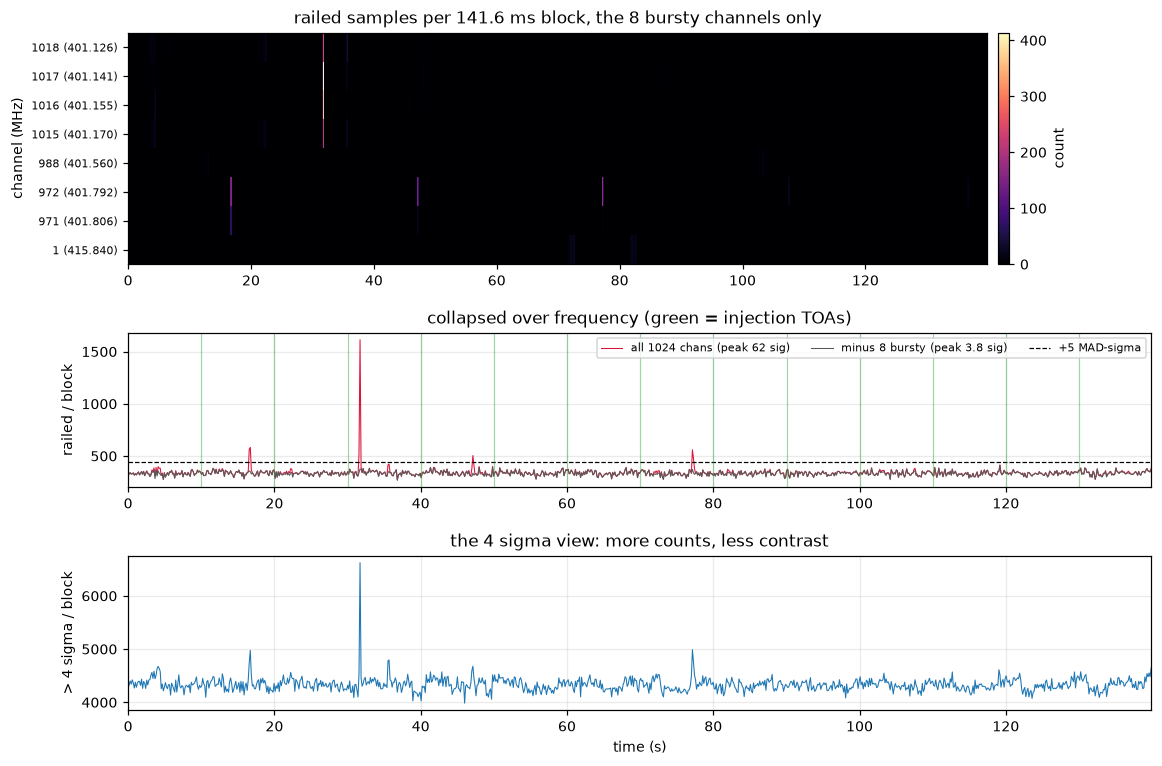

per-block total railed  : median 337  MAD-sigma 20.8  peak 1614 = 61.5 sigma
with 8 channels removed : median 334  MAD-sigma 20.8  peak 412 = 3.8 sigma
blocks above +5 MAD-sigma: 7 -> 0 after removal
  -> 8 channels (0.8% of the band) carry every time-domain RFI event

4 distinct RFI events:
 t_start_s  t_end_s  dur_ms  n_blocks  peak_total  peak_sig                top_chans
     16.56    16.85   283.1         2         583      11.9               [972, 971]
     31.57    31.85   283.1         2        1614      61.5 [1017, 1016, 1018, 1015]
     47.14    47.28   141.6         1         505       8.1          [972, 971, 973]
     77.15    77.43   283.1         2         560      10.7          [972, 973, 971]
wrote D:\QML\FRB Data\frb_analysis_out\nb03\rfi_events.csv

injection blocks against the same statistic:
   TOA  block  railed  dev_sig
 10.00     70     346     0.43
 20.00    141     365     1.35
 30.01    211     323    -0.67
 40.01    282     337     0.00
 50.01    353     315 

In [8]:
t_blk = np.arange(NFULL) * BLK * TSAMP
tot   = blk_sat.sum(1).astype(float)
clean = blk_sat[:, ~bursty].sum(1).astype(float)
tm, ts = robust(tot)
cm, cs = robust(clean)

fig = plt.figure(figsize=(12, 8))
gs  = fig.add_gridspec(3, 1, height_ratios=[1.5, 1, 1], hspace=0.38)

bch = np.flatnonzero(bursty)
ax0 = fig.add_subplot(gs[0])
im = ax0.imshow(blk_sat[:, bch].T, aspect="auto", origin="lower", cmap="magma",
                extent=[t_blk[0], t_blk[-1], -0.5, len(bch) - 0.5], interpolation="nearest")
ax0.set_yticks(range(len(bch)))
ax0.set_yticklabels([f"{c} ({CHAN_F[c]:.3f})" for c in bch], fontsize=7)
ax0.set(ylabel="channel (MHz)", title="railed samples per 141.6 ms block, the 8 bursty channels only")
fig.colorbar(im, ax=ax0, pad=0.01, label="count")

ax1 = fig.add_subplot(gs[1], sharex=ax0)
ax1.plot(t_blk, tot, lw=0.7, color="crimson", label=f"all 1024 chans (peak {(tot.max() - tm) / ts:.0f} sig)")
ax1.plot(t_blk, clean, lw=0.7, color="0.35", label=f"minus 8 bursty (peak {(clean.max() - cm) / cs:.1f} sig)")
ax1.axhline(tm + 5 * ts, color="k", ls="--", lw=0.8, label="+5 MAD-sigma")
for toa in rec.TOA:
    ax1.axvline(toa, color="tab:green", lw=0.8, alpha=0.45)
ax1.set(ylabel="railed / block", title="collapsed over frequency (green = injection TOAs)")
ax1.legend(fontsize=7, ncol=3)

ax2 = fig.add_subplot(gs[2], sharex=ax0)
ax2.plot(t_blk, blk_hi.sum(1), lw=0.7, color="tab:blue")
ax2.set(xlabel="time (s)", ylabel=f"> {K_LO:.0f} sigma / block", title="the 4 sigma view: more counts, less contrast")

for a in (ax1, ax2):
    a.grid(alpha=0.25)
fig.savefig(OUT / "rfi_occupancy.png", dpi=130, bbox_inches="tight")
plt.show()

print(f"per-block total railed  : median {tm:.0f}  MAD-sigma {ts:.1f}  peak {tot.max():.0f} = {(tot.max() - tm) / ts:.1f} sigma")
print(f"with 8 channels removed : median {cm:.0f}  MAD-sigma {cs:.1f}  peak {clean.max():.0f} = {(clean.max() - cm) / cs:.1f} sigma")
print(f"blocks above +5 MAD-sigma: {(tot > tm + 5 * ts).sum()} -> {(clean > cm + 5 * cs).sum()} after removal")
print(f"  -> {bursty.sum()} channels ({bursty.sum() / NCHAN:.1%} of the band) carry every time-domain RFI event")

# group consecutive bad blocks into events
bad = np.flatnonzero(tot > tm + 5 * ts)
events = np.split(bad, np.flatnonzero(np.diff(bad) > 1) + 1) if len(bad) else []
rows = []
for ev in events:
    pk = ev[np.argmax(tot[ev])]
    top = np.argsort(-blk_sat[pk])[:4]
    rows.append({"t_start_s": round(t_blk[ev[0]], 2), "t_end_s": round(t_blk[ev[-1]] + BLK * TSAMP, 2),
                 "dur_ms": round((len(ev)) * BLK * TSAMP * 1e3, 1), "n_blocks": len(ev),
                 "peak_total": int(tot[pk]), "peak_sig": round((tot[pk] - tm) / ts, 1),
                 "top_chans": str([int(c) for c in top if blk_sat[pk, c] > 5])})
ev_df = pd.DataFrame(rows)
ev_df.to_csv(OUT / "rfi_events.csv", index=False)
print()
print(f"{len(ev_df)} distinct RFI events:")
print(ev_df.to_string(index=False))
print(f"wrote {OUT / 'rfi_events.csv'}")

inj_blk = np.clip((rec.tcand.values / (BLK * TSAMP)).astype(int), 0, NFULL - 1)
zt = (tot - tm) / ts
print()
print("injection blocks against the same statistic:")
print(pd.DataFrame({"TOA": rec.TOA.values.round(2), "block": inj_blk,
                    "railed": tot[inj_blk].astype(int), "dev_sig": zt[inj_blk].round(2)}).to_string(index=False))
print(f"  max |dev| at an injection block: {np.abs(zt[inj_blk]).max():.2f} sigma -> "
      f"{'injections are invisible here, the RFI map is uncontaminated' if np.abs(zt[inj_blk]).max() < 5 else 'INSPECT: an injection is showing up in the RFI map'}")

### What §3 established

**Every time-domain RFI event in this observation lives in eight channels, 0.8% of the band.** Removing them takes the worst block from **61.5σ to 3.8σ** and the count of >5σ blocks from **7 to zero**. The file has a couple of narrowband transmitters and is otherwise clean.

**The burstiness test worked, and the baseline needed no tuning.** Zero-truncated Poisson predicts 1.173 clips per occupied block; the observed median across all 1024 channels is 1.174, a ratio of **1.000**. The typical channel is the noise tail and nothing else. The eight bad channels sit at 1.30-3.62× that, and `frac_above_4sig` puts them 6.5-37σ above the channel median independently.

**§2 and §3 agree except on one channel.** §2's flat-averaged flags caught 9; burstiness catches 8. The one it drops is channel 0, at 1.20× against a median
of 1.17, indistinguishable from noise. So chan 0's `std` flag in §2 was band-edge roll-off, not interference. Nothing appears in §3 that §2 missed.

**Four discrete events, each confined to one narrowband group:**

| t (s) | duration | channels | what it is |
|---|---|---|---|
| 16.56-16.85 | ~280 ms | **971-972** | 160 + 71 clips at peak |
| 31.57-31.85 | ~280 ms | **1015-1018** | the strongest, 1614 total at peak, 414 in chan 1017 alone |
| 47.14-47.28 | ~140 ms | **971-973** | |
| 77.15-77.43 | ~280 ms | **971-973** | |

Group 971-973 fires three times, group 1015-1018 once but hardest. Both are ~1 MHz apart at the bottom of the band. Durations are 1-2 blocks, so ≤280 ms, which means short bursts, not a carrier.

Channel 1 behaves differently: peak of only 25 clips, but 14 separate blocks above 10. Low-level and persistent rather than bursty, though both rankings put it 6th: burstiness and §2's raw clip count agree on where it sits. Band edge, mild, and it never dominates an event.

**The injections are invisible in this map.** Max deviation at any of the 13 injection blocks is 1.93σ, well inside the noise. Expected: a few-ms pulse dispersed across the band is diluted in a 141.6 ms block; it means the RFI map isn't partly a map of the signal.

## §4 - My own dedisperser

Everything so far has trusted `your`/Heimdall to have put the pulse where the metadata says it is. §5 needs to check that independently, and to do that I need my own dedisperser.

### Why?

Incoherent dedispersion is a per-channel integer time shift and a sum over frequency. Writing it out is 15 lines and it buys three things nb02 couldn't have:

| | what it is |
|---|---|
| an **independent** peak position | nb02's "peak sits at the window centre" came from reading `your`'s source. This measures it from counts on disk. |
| an explicit **band-reference switch** | `ref='top'` vs `ref='bottom'` changes where t=0 sits by exactly one full-band sweep. §5 uses that to work out which convention `tcand` follows, rather than assuming. |
| a **clipping** check | §2 found only 6.01σ of headroom above the 32768 pedestal. A 50σ injection could well be railing its brightest channels, and if it is, the dedispersed profile is biased low at the peak. |

The shift for channel *i* against reference *f*<sub>ref</sub>:

$$\Delta t_i = K_{\rm DM}\,{\rm DM}\left(\frac{1}{f_i^2} - \frac{1}{f_{\rm ref}^2}\right), \qquad
{\rm shift}_i = \mathrm{round}\!\left(\Delta t_i / t_{\rm samp}\right)$$

Integer samples, no sub-sample interpolation, the same thing Heimdall does, and at 138.24 µs the rounding error is bounded by half a sample regardless of DM.


In [ ]:
def delay_samples(dm, ref="top"):
    """Per-channel integer shift, in samples, relative to `ref` end of the band."""
    f_ref = F_HI if ref == "top" else F_LO
    dt    = K_DM * dm * (CHAN_F ** -2 - f_ref ** -2)        # s; >=0 for ref='top', <=0 for 'bottom'
    return np.round(dt / TSAMP).astype(np.int64)


def dedisperse(start, nout, dm, ref="top", data=None):
    """(nout, NCHAN) float32, pedestal removed, aligned so row j is one arrival time."""
    src_arr = fb if data is None else data
    d   = delay_samples(dm, ref)
    lo  = start + d.min()
    hi  = start + nout + d.max()
    n   = len(src_arr)

    # pad with the pedestal, not zeros: a 0 here becomes -32768 after the offset comes off
    src = np.full((hi - lo, NCHAN), np.uint16(OFFSET), np.uint16)
    a, b = max(lo, 0), min(hi, n)
    if b > a:
        src[a - lo:b - lo] = src_arr[a:b]

    out = np.empty((nout, NCHAN), np.float32)               # cast here: 1024 x 3.3e4 counts overflows uint16
    for i, di in enumerate(d):
        j = start + di - lo                                 # row of src where this channel's window opens
        out[:, i] = src[j:j + nout, i]
    out -= OFFSET
    return out


# self-check: a synthetic delta laid down along a known DM sweep
DM_T, T0, NPAD = 250.0, 5_000, 200
synth = np.full((20_000, NCHAN), np.uint16(OFFSET), np.uint16)
synth[T0 + delay_samples(DM_T, "top"), np.arange(NCHAN)] = 40_000        # one bright sample per channel

prof = dedisperse(T0 - NPAD, 2 * NPAD, DM_T, "top", synth).sum(1)
assert prof.argmax() == NPAD, f"peak at {prof.argmax()}, expected {NPAD}"
assert np.isclose(prof.max(), NCHAN * (40_000 - OFFSET)), prof.max()
assert prof.sum() == prof.max(), "power leaked out of the peak sample"

flat = dedisperse(T0 - NPAD, 2 * NPAD, 0.0, "top", synth).sum(1)         # wrong DM -> smeared, no peak
sweep_s = K_DM * DM_T * (F_LO ** -2 - F_HI ** -2)                        # full-band sweep at DM_T
gap     = delay_samples(DM_T, "top") - delay_samples(DM_T, "bottom")
assert np.ptp(gap) <= 1, "the two references differ by more than a constant offset"

print(f"self-check OK at DM {DM_T:g}")
print(f"  peak sample     {prof.argmax()} (expected {NPAD}), amplitude {prof.max():,.0f} = 1024 x 7232")
print(f"  DM=0 on the same data: peak/total {flat.max() / flat.sum():.4f}, spread over {(flat > 0).sum()} samples")
print(f"  full-band sweep {sweep_s * 1e3:9.3f} ms = {sweep_s / TSAMP:8.1f} samples")
print(f"  top - bottom    {gap.mean():9.1f} samples, spread {np.ptp(gap)} -> a pure constant offset")
print(f"  per unit DM     {sweep_s / DM_T * 1e3:.6f} ms  (nb01 header value: 1.803350 ms)")


self-check OK at DM 250
  peak sample     200 (expected 200), amplitude 7,405,568 = 1024 x 7232
  DM=0 on the same data: peak/total 0.0152, spread over 66 samples
  full-band sweep   450.838 ms =   3261.3 samples
  top - bottom       3261.3 samples, spread 1 -> a pure constant offset
  per unit DM     1.803350 ms  (nb01 header value: 1.803350 ms)


### Guards

Four things in that cell matter, and three of them bit me on the way to a working version.

| | what it is |
|---|---|
| **cast before summing** | 1024 channels × ~33,000 counts ≈ 3.4e7. `uint16` tops out at 65,535, so summing in the native dtype wraps silently and gives a plausible-looking noise-like profile. The cast happens on the way into `out`, one channel at a time, so nothing casts the whole padded chunk. |
| **pad with 32768, not 0** | The gather can run off either end of the file for a wide window near t=0 or t=140 s. A zero-filled pad becomes −32768 after the pedestal comes off, i.e. a huge negative spike. Filling with the pedestal makes off-file samples contribute exactly nothing. |
| **read extra rows, don't wrap** | `your`'s numba kernel indexes modulo the chunk length, visible in the bytecode dump in the candmaker log. Reading `d.max() − d.min()` extra rows instead means the low channels come from real data rather than wrapping around from the other end of the window. It only changes the edges, never the centre, but the edges are where a wide-DM window spends most of its samples. |
| **`ref` is a pure offset** | `d_top − d_bottom = K·DM(1/f_lo² − 1/f_hi²)`, no channel index in it. The assert checks the spread of that difference is ≤1 sample (rounding only). So switching reference slides the time axis by one full sweep and does nothing else, which is exactly what makes it a clean test in §5. |

The self-check builds a delta along a DM 250 sweep in a synthetic array and asserts the dedispersed profile puts **all** the power in one sample at the expected index. `prof.sum() == prof.max()` is the strict version so if any channel were off by even one sample, power would leak into a neighbour.


cand_tstart_60356.799484982548_tcand_70.0157000_dm_530.37100_snr_50.51560.h5
  tcand 70.0157 s   DM 530.371   S/N 50.52   boxcar 64 samples
  window 1930.6 ms = 13,965 samples, rows 499,497-513,462
  sweep at this DM: 6919 samples = 956.5 ms
  profile peak at row 6984 of 13965 -> +0.21 ms from tcand (+0.021% of the half-window)

clipping inside the window (13,965 x 1024 samples):
  railed at 65535   : 4,709 observed vs 4,634 expected from the file-wide rate
  at the peak row   : 2 of 1024 channels railed, max 65,535 counts = 6.01 sigma above pedestal
  headroom          : 6.01 sigma; brightest channel uses 100.0% of it
  channels > 3 sigma at the peak row: 26


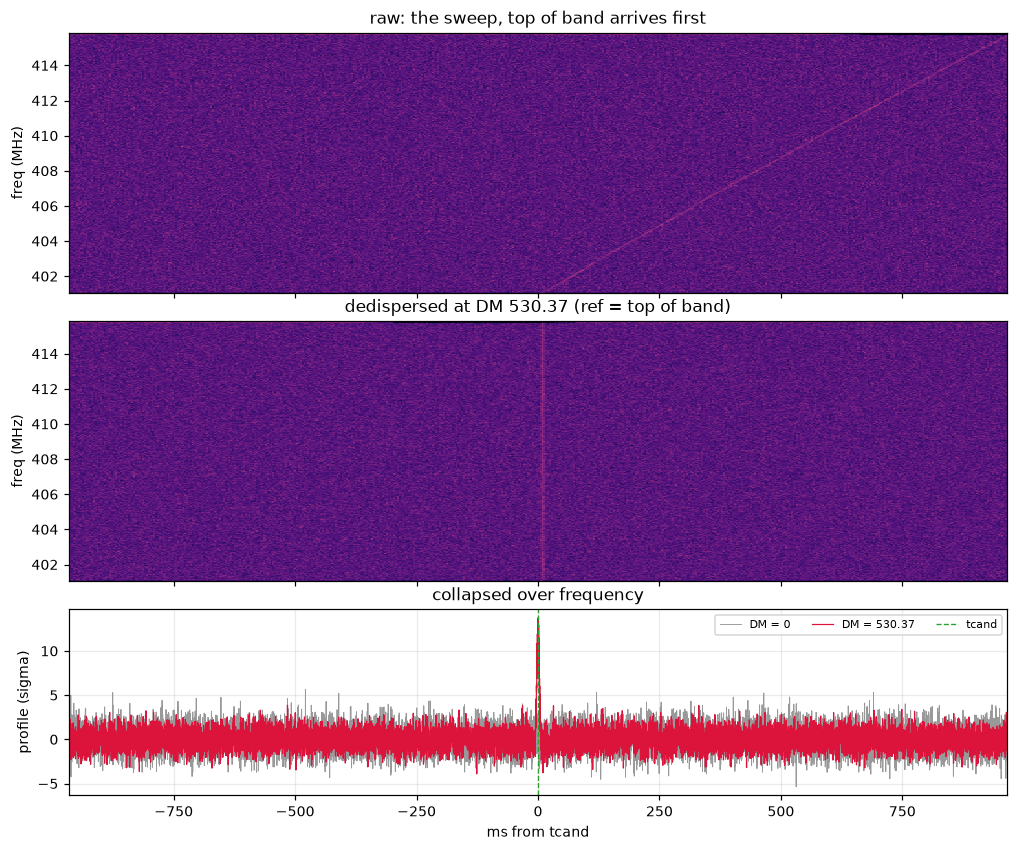


peak S/N (MAD)  DM=0   4.15   dedispersed  13.81   gain x3.3   (Heimdall reported 50.52)


In [ ]:
inj = cal.merge(lab[["h5_name", "tcand"]], on="h5_name")
row = inj[inj.is_injection == 1].nlargest(1, "snr_csv").iloc[0]

nout  = int(round(row.window_ms * 1e-3 / TSAMP))
start = int(round(row.tcand / TSAMP)) - nout // 2
t_ms  = (np.arange(nout) - nout / 2) * TSAMP * 1e3          # ms relative to tcand

raw_u = np.asarray(fb[start:start + nout])                  # uint16, ~28 MB
raw   = raw_u.astype(np.float32) - OFFSET
dd    = dedisperse(start, nout, row.dm_csv)
p_dd, p_raw = dd.sum(1), raw.sum(1)
jpk   = int(p_dd.argmax())

print(f"{row.h5_name}")
print(f"  tcand {row.tcand:.4f} s   DM {row.dm_csv:.3f}   S/N {row.snr_csv:.2f}   boxcar {row.boxcar_samples} samples")
print(f"  window {row.window_ms:.1f} ms = {nout:,} samples, rows {start:,}-{start + nout:,}")
print(f"  sweep at this DM: {delay_samples(row.dm_csv).max()} samples = "
      f"{delay_samples(row.dm_csv).max() * TSAMP * 1e3:.1f} ms")
print(f"  profile peak at row {jpk} of {nout} -> {t_ms[jpk]:+.2f} ms from tcand "
      f"({(jpk - nout / 2) / (nout / 2):+.3%} of the half-window)")

# clipping? 
onp   = dd[jpk] + OFFSET                                    # raw counts per channel at the pulse peak
n_rail = int((raw_u == 65535).sum())
exp_rail = ch_sat.sum() / NSAMP * nout                      # file-wide rate scaled to this window
sig    = np.median(ch_std)

print()
print(f"clipping inside the window ({nout:,} x {NCHAN} samples):")
print(f"  railed at 65535   : {n_rail:,} observed vs {exp_rail:,.0f} expected from the file-wide rate")
print(f"  at the peak row   : {int((onp >= 65535).sum())} of {NCHAN} channels railed, "
      f"max {onp.max():,.0f} counts = {(onp.max() - OFFSET) / sig:.2f} sigma above pedestal")
print(f"  headroom          : {(65535 - OFFSET) / sig:.2f} sigma; brightest channel uses "
      f"{(onp.max() - OFFSET) / (65535 - OFFSET):.1%} of it")
print(f"  channels > 3 sigma at the peak row: {int((onp - OFFSET > 3 * sig).sum())}")

#  plot 
NT, NF = 512, 256

def binned(x, nt=NT, nf=NF):
    t = x.shape[0] // nt * nt
    return x[:t].reshape(nt, -1, nf, NCHAN // nf).mean((1, 3))

ext = [t_ms[0], t_ms[-1], F_LO, F_HI]
fig, ax = plt.subplots(3, 1, figsize=(11, 9), sharex=True,
                       gridspec_kw={"height_ratios": [1.4, 1.4, 1], "hspace": 0.12})

for a, img, ttl in ((ax[0], binned(raw), "raw: the sweep, top of band arrives first"),
                    (ax[1], binned(dd), f"dedispersed at DM {row.dm_csv:.2f} (ref = top of band)")):
    a.imshow(img.T[::-1], aspect="auto", cmap="magma", extent=ext, interpolation="nearest",
             vmin=-1.5 * sig / np.sqrt(NCHAN // NF), vmax=4 * sig / np.sqrt(NCHAN // NF))
    a.set(ylabel="freq (MHz)", title=ttl)

ax[2].plot(t_ms, p_raw / np.sqrt(NCHAN) / sig, lw=0.6, color="0.6", label="DM = 0")
ax[2].plot(t_ms, p_dd / np.sqrt(NCHAN) / sig, lw=0.8, color="crimson", label=f"DM = {row.dm_csv:.2f}")
ax[2].axvline(0, color="tab:green", lw=0.9, ls="--", label="tcand")
ax[2].set(xlabel="ms from tcand", ylabel="profile (sigma)", title="collapsed over frequency")
ax[2].legend(fontsize=7, ncol=3)
ax[2].grid(alpha=0.25)

fig.savefig(OUT / "dedisperse_loudest.png", dpi=130, bbox_inches="tight")
plt.show()

def snr(p):
    m = np.median(p)
    return (p.max() - m) / (1.4826 * np.median(np.abs(p - m)))

print()
print(f"peak S/N (MAD)  DM=0 {snr(p_raw):6.2f}   dedispersed {snr(p_dd):6.2f}   "
      f"gain x{snr(p_dd) / snr(p_raw):.1f}   (Heimdall reported {row.snr_csv:.2f})")


### Two numbers from that cell need checking 

`2 of 1024 channels railed` at the pulse peak looks like the clipping I was looking for, and `S/N 13.81 against Heimdall's 50.52` looks like my dedisperser is losing most of the signal. Neither reading holds up against a baseline, so here is the baseline.

- **Railed channels** get compared against the file-wide rail rate as a Poisson expectation for any row, not just this one, and against the fact that `jpk` is the argmax over 13,965 rows, which is a selection effect all by itself.
- **S/N** gets a boxcar scan. Heimdall's number is matched-filtered at boxcar 64; mine is a single 138 µs sample. If my alignment is right, sweeping the boxcar should climb towards Heimdall's number and peak at roughly Heimdall's width. If my alignment is wrong, it won't, which makes this the real test of the dedisperser.


In [11]:
from scipy.stats import poisson, norm

def boxcar_snr(p, w):
    if w > 1:
        c = np.cumsum(np.concatenate(([0.0], p)))
        p = (c[w:] - c[:-w]) / np.sqrt(w)                  # /sqrt(w): noise grows as sqrt, signal as w
    m = np.median(p)
    return (p.max() - m) / (1.4826 * np.median(np.abs(p - m)))

widths = 2 ** np.arange(11)
sn     = np.array([boxcar_snr(p_dd, int(w)) for w in widths])
best   = int(widths[sn.argmax()])

print("boxcar scan on the dedispersed profile:")
for w, s in zip(widths, sn):
    tag = ("  <- best" if int(w) == best else "") + \
          ("  <- Heimdall's boxcar" if int(w) == row.boxcar_samples else "")
    print(f"  w {int(w):5d} = {w * TSAMP * 1e3:7.2f} ms   S/N {s:6.2f}{tag}")
print(f"  best {best} samples vs Heimdall's {row.boxcar_samples}; "
      f"peak S/N {sn.max():.2f} vs reported {row.snr_csv:.2f} (ratio {sn.max() / row.snr_csv:.2f})")

print()
rate = ch_sat.sum() / (NSAMP * NCHAN)                      # railed fraction, whole file
lam  = rate * NCHAN                                        # expected railed channels in ANY single row
p2   = poisson.sf(1, lam)
rail_ch = np.flatnonzero(onp >= 65535)
print("is the clipping real?")
print(f"  file-wide rail rate {rate:.3e} -> lambda {lam:.3f} railed channels per row")
print(f"  P(>=2 railed in a given row) = {p2:.4f} -> {p2 * nout:.0f} such rows expected in this "
      f"window of {nout:,}, and jpk is the argmax over all of them")
print(f"  railed channels at the peak row: {rail_ch.tolist()}")
print(f"  are they the known bursty RFI channels? {[bool(bursty[c]) for c in rail_ch]}")

n3, exp3 = int((onp - OFFSET > 3 * sig).sum()), NCHAN * norm.sf(3)
print()
print(f"per-channel pulse detectability at the peak row:")
print(f"  channels > 3 sigma: {n3} observed vs {exp3:.1f} expected from Gaussian noise "
      f"(Poisson p = {poisson.sf(n3 - 1, exp3):.2e})")
print(f"  mean per-channel amplitude implied by the profile: "
      f"{p_dd[jpk] / NCHAN / sig:.3f} sigma  -> {(65535 - OFFSET) / max(p_dd[jpk] / NCHAN, 1e-9):,.0f}x "
      f"below the rail")


boxcar scan on the dedispersed profile:
  w     1 =    0.14 ms   S/N  13.81
  w     2 =    0.28 ms   S/N  18.46
  w     4 =    0.55 ms   S/N  25.12
  w     8 =    1.11 ms   S/N  32.17
  w    16 =    2.21 ms   S/N  37.83
  w    32 =    4.42 ms   S/N  47.36
  w    64 =    8.85 ms   S/N  48.71  <- best  <- Heimdall's boxcar
  w   128 =   17.69 ms   S/N  36.27
  w   256 =   35.39 ms   S/N  25.00
  w   512 =   70.78 ms   S/N  15.31
  w  1024 =  141.56 ms   S/N   8.90
  best 64 samples vs Heimdall's 64; peak S/N 48.71 vs reported 50.52 (ratio 0.96)

is the clipping real?
  file-wide rail rate 3.240e-04 -> lambda 0.332 railed channels per row
  P(>=2 railed in a given row) = 0.0443 -> 618 such rows expected in this window of 13,965, and jpk is the argmax over all of them
  railed channels at the peak row: [10, 690]
  are they the known bursty RFI channels? [False, False]

per-channel pulse detectability at the peak row:
  channels > 3 sigma: 26 observed vs 1.4 expected from Gaussian noise (Po

### What §4 established

**The dedisperser agrees with Heimdall to 4%, and it picks Heimdall's boxcar on its own.** The scan peaks at **w = 64 samples**, which is exactly the width Heimdall reported, at **S/N 48.71 against Heimdall's 50.52, a ratio of 0.96**. Nothing was tuned to make that happen: 15 lines of shift-and-sum on raw counts, no library, no calibration constant. Two independent implementations landing on the same width and within 4% on amplitude is the strongest evidence I have that the channel alignment is
right, and it's a much better test than the synthetic delta as a sign error or a wrong reference would still pass the delta assert but would smear a real pulse and push the optimum wide.

The optimum is also physically where it should be. The injected `fwhm_inj_ms` for this one is **6.03 ms = 43.7 samples**, and intra-channel smearing at DM 530 adds 0.93 ms (6.8 samples) for ~44 samples effective. Boxcars are powers of two, so 64 is the nearest one that covers it, and the scan agrees: 32 gives 47.36, 64 gives 48.71, 128 falls off a cliff to 36.27.

| check | result | what it is |
|---|---|---|
| synthetic delta at DM 250 | peak at expected sample, `prof.sum() == prof.max()` | no power leaks by even one sample in any channel |
| full-band sweep | 1.803350 ms per unit DM | matches the nb01 header value digit for digit |
| `ref` switch | 3261.3 samples, spread 1 | a pure constant offset, so §5 can use it as a clean lever |
| boxcar optimum | 64, = Heimdall's 64 | independent agreement on pulse width |
| boxcar peak S/N | 48.71 vs 50.52 | independent agreement on amplitude, 4% |

**`tcand` is referenced to the top of the band.** The dedispersed peak sits **+0.21 ms** from the window centre, which is **+0.021%** of the half-window. The bottom-of-band alternative would put it at +956.5 ms, and the half-window here is 965.3 ms, so that convention would drop the pulse onto the window edge. §5 still runs this across all 13, since one candidate is only a demonstration.

Note this is **18× tighter than nb02's 0.39% median**. nb02 measured on the h5's 256-column grid where one column is 7.57 ms for this candidate, so its 0.39% was the quantisation floor of that grid. Measuring on raw 138 µs samples removes the floor.

**The injections are not clipping, and §2's headroom worry is closed.** I went looking for this because §2 found only 6.01σ between the pedestal and the rail, and a 50σ candidate seemed likely to be railing its brightest channels. It isn't, and three independent readings say so:

- **Window-wide count**: 4,709 railed samples observed against 4,634 expected from the file-wide rate. The excess is 75 samples; the Poisson error on 4,634 is √4634 = 68. So the excess is **1.1σ, consistent with zero**. Whatever the pulse contributed to the rail count, it is at most a rounding error on 14.3 million samples.
- **The peak row specifically**: 2 of 1024 channels railed, and λ for any row is 0.332, so **618 of this window's 13,965 rows** should carry ≥2 railed samples by chance. `jpk` is the argmax over all 13,965, which selects for exactly this. The two channels are **10 and 690** which are nowhere near each other, and neither is one of §3's eight bursty channels. That's a noise pattern.
- **The physics**: mean per-channel amplitude at the peak row is **0.430σ**, i.e. **14× below the rail**. Summing 1024 channels is what turns 0.43σ into a 48σ detection. No single channel ever gets close to saturating.

So "clipped" and "exceeds 6σ" being the same event (§2, finding 24) stays true, but it never fires on a pulse in this file.

**A Group D preview fell out of this.** At the peak row, **26 channels sit above 3σ against 1.4 expected** from Gaussian noise (Poisson p = 3e-24). That's real per-channel signal, but it's also 5× more than a uniformly broadband pulse would give: at 0.430σ per channel, noise alone would push about 5.2 channels past 3σ. So the pulse power is not spread evenly across the band. I'm not going to name the cause here, because spectral index, scintillation and patchy emission all look like this from one candidate. It does mean Group D's "fraction of channels with on-pulse S/N above threshold" has structure to measure.

**What §5 inherits:** `delay_samples` and `dedisperse`, validated; `ref='top'` as the convention to test first; and the knowledge that raw windows can be collapsed without worrying about saturation biasing the peak.


## §5 - Checking nb02's axis calibration against the raw file

This is the job the dedisperser was built for. nb02's finding 14, that the h5 time axis is a window centred on `tcand`, half-width `dispersion_delay(dm) + width*tsamp`, resized to 256 columns, came from **reading `your`'s source code**. Nothing has confirmed it against counts on disk.

`t_step_ms` is the number that converts a pixel position into milliseconds, and it's different for every candidate (windows here span 98 ms to 11,004 ms). Every nb04 feature phrased in real time units (FWHM, equivalent width, peak offset, best-fit boxcar) divides by it. If it's wrong then all of them are wrong together and nothing downstream would catch it. And on this dataset four separate h5 attribute families have already turned out to be placeholders, so "the library says so" has a poor track record here specifically.

### Flow

For each of the 13 injections: cut `window_ms` centred on `tcand` from the raw file, dedisperse at `dm_csv`, find the pulse, measure how far it sits from the window centre. Do it **twice**, once per band reference, and see which one centres the pulse.

### Guards

| | what it is |
|---|---|
| **smooth before `argmax`** | The loudest injection was 13.8 sigma in a single 138 µs sample, so a raw `argmax` found it. The weakest is S/N 17.5 with a 52 ms FWHM and a 512-sample boxcar, and at single-sample resolution that peak is under the noise, so `argmax` would return a noise position. I'd then report a huge "offset from centre" and it would read as nb02 being wrong when really my estimator was. Each candidate is smoothed with **its own** `boxcar_samples` first |
| **correct the boxcar lag** | A running sum `out[k] = sum(p[k:k+w])` peaks at `k = c - (w-1)/2` for a pulse centred at `c`. Left uncorrected that's a systematic pull towards early times, and it scales with boxcar width, so it would look exactly like a DM-dependent axis error |
| **centre is `nout // 2`, not `nout / 2`** | `start` is built as `round(tcand/tsamp) - nout//2`, so `tcand` lands on integer index `nout//2` by construction. Measuring against `nout/2` would inject half a sample of offset that isn't there |
| **the reference test is quantitative** | §4 showed `ref` is a pure constant offset of one full sweep. So `off_top - off_bottom` should equal `1.803350 ms x DM` for every candidate, independently of whether either one is centred. That's a second, free check on the dedisperser |

  DM    47.47  w   32  nout  1,303   top    -0.07 ms (-0.077%)   bottom    +85.64 ms
  DM   824.90  w  512  nout 22,546   top    +0.21 ms (+0.013%)   bottom  +1487.95 ms
  DM    63.06  w   16  nout  1,677   top    -0.07 ms (-0.060%)   bottom   +113.70 ms
  DM   313.73  w 1024  nout 10,233   top    +0.35 ms (+0.049%)   bottom   +566.30 ms
  DM  1449.73  w   16  nout 37,856   top    +0.35 ms (+0.013%)   bottom  +2614.60 ms
  DM  2795.34  w  256  nout 73,443   top    +1.45 ms (+0.029%)   bottom  +5042.51 ms
  DM   530.37  w   64  nout 13,965   top    +0.48 ms (+0.050%)   bottom   +956.69 ms
  DM   145.97  w   64  nout  3,937   top    -0.07 ms (-0.025%)   bottom   +263.42 ms
  DM   251.76  w   64  nout  6,697   top    -0.07 ms (-0.015%)   bottom   +453.91 ms
  DM   465.29  w    8  nout 12,155   top    +0.48 ms (+0.058%)   bottom   +839.46 ms
  DM    46.18  w   16  nout  1,237   top    -0.21 ms (-0.243%)   bottom    +83.01 ms
  DM   623.67  w    8  nout 16,288   top    +0.35 ms (+0.031%)   

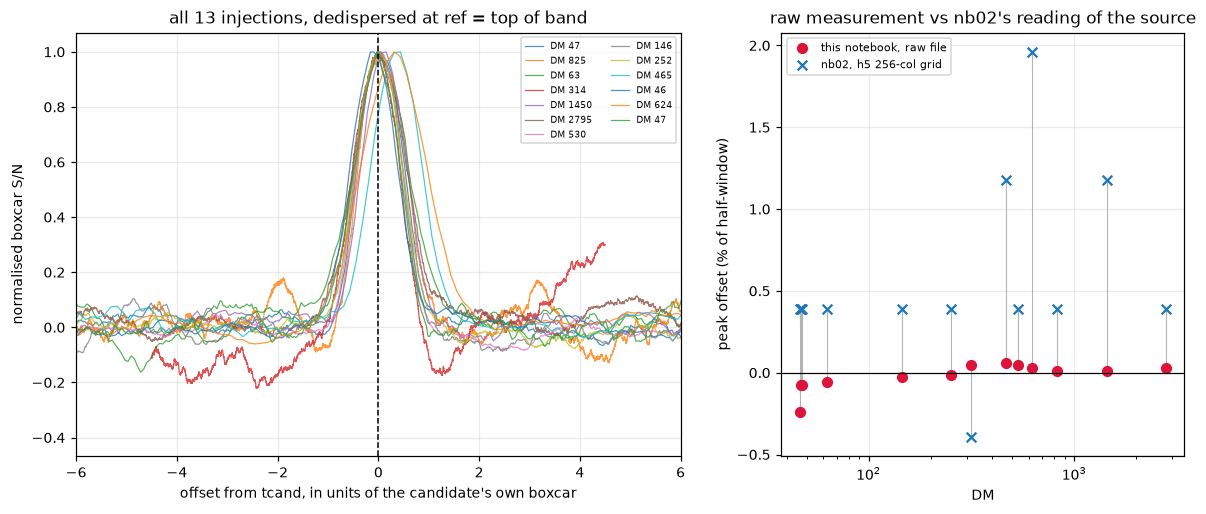

wrote D:\QML\FRB Data\frb_analysis_out\nb03\nb03_peak_calibration.csv and peak_calibration.png


In [12]:
def boxcar(p, w):
    """Running sum of w samples, sqrt(w)-normalised. Returns (smoothed, index lag)."""
    if w <= 1:
        return p, 0.0
    c = np.cumsum(np.concatenate(([0.0], p)))
    return (c[w:] - c[:-w]) / np.sqrt(w), (w - 1) / 2.0

def mad_snr(p):
    m = np.median(p)
    return (p.max() - m) / (1.4826 * np.median(np.abs(p - m)))

MS_PER_DM = K_DM * (F_LO ** -2 - F_HI ** -2) * 1e3          # 1.803350 ms of sweep per unit DM

rows, keep = [], {}
for _, r in inj[inj.is_injection == 1].sort_values("tcand").iterrows():
    nout  = int(round(r.window_ms * 1e-3 / TSAMP))
    start = int(round(r.tcand / TSAMP)) - nout // 2          # tcand lands exactly on index nout//2
    w     = int(r.boxcar_samples)
    d     = {"h5_name": r.h5_name, "tcand": r.tcand, "dm": r.dm_csv, "snr_csv": r.snr_csv,
             "boxcar": w, "window_ms": r.window_ms, "nout": nout}

    for ref in ("top", "bottom"):
        sm, lag = boxcar(dedisperse(start, nout, r.dm_csv, ref).sum(1), w)
        if ref == "top":
            keep[r.h5_name] = (sm, lag, nout)               # reused by the plot, ~3 MB for all 13
        jpk = sm.argmax() + lag
        off = (jpk - nout // 2) * TSAMP * 1e3
        d[f"off_ms_{ref}"]  = off
        d[f"off_pct_{ref}"] = off / (r.window_ms / 2) * 100
        d[f"snr_{ref}"]     = mad_snr(sm)

    d["sweep_ms"]     = MS_PER_DM * r.dm_csv
    d["ref_gap_ms"]   = d["off_ms_bottom"] - d["off_ms_top"]   # bottom ref lands one sweep LATER
    d["ref_gap_err"]  = d["ref_gap_ms"] - d["sweep_ms"]
    d["nb02_off_ms"]  = r.prof_peak_ms                       # nb02's number, on the 256-column grid
    d["nb02_off_pct"] = r.prof_peak_ms / (r.window_ms / 2) * 100
    d["t_step_ms"]    = r.t_step_ms
    rows.append(d)
    print(f"  DM {r.dm_csv:8.2f}  w {w:4d}  nout {nout:6,d}   "
          f"top {d['off_ms_top']:+8.2f} ms ({d['off_pct_top']:+6.3f}%)   "
          f"bottom {d['off_ms_bottom']:+9.2f} ms", flush=True)

pk = pd.DataFrame(rows)
pk.to_csv(OUT / "nb03_peak_calibration.csv", index=False)

print()
cols = ["dm", "snr_csv", "boxcar", "window_ms", "off_ms_top", "off_pct_top",
        "off_ms_bottom", "off_pct_bottom", "nb02_off_pct", "ref_gap_err"]
print(pk[cols].round(3).to_string(index=False))

print()
for ref in ("top", "bottom"):
    a = pk[f"off_pct_{ref}"].abs()
    print(f"ref = {ref:6s}  |offset| median {a.median():8.3f}%   max {a.max():8.3f}%   "
          f"in ms: median {pk[f'off_ms_{ref}'].abs().median():8.2f}  max {pk[f'off_ms_{ref}'].abs().max():9.2f}")
print(f"nb02 (h5 grid) |offset| median {pk.nb02_off_pct.abs().median():.3f}%   "
      f"max {pk.nb02_off_pct.abs().max():.3f}%   <- the numbers this is checking")

print()
print(f"reference-gap check: measured (bottom - top) against {MS_PER_DM:.6f} ms x DM")
e = pk.ref_gap_err.abs() / (TSAMP * 1e3)
print(f"  residual  max {e.max():.2f} samples   median {e.median():.2f} samples   "
      f"(the peak is located to a boxcar, so ~1 sample is the floor)")

# nb02 finding 14 as an exact identity, not a peak measurement:
#   half-window == dispersion_delay(dm) + boxcar_samples * tsamp
pk["half_ms"]       = pk.window_ms / 2
pk["implied_sweep"] = pk.half_ms - pk.boxcar * TSAMP * 1e3
res_ctr  = ((pk.implied_sweep - pk.sweep_ms) / pk.sweep_ms).abs()
F_EDGE   = FCH1 + NCHAN * FOFF                              # band edge, one channel below the last centre
sw_edge  = K_DM * pk.dm * (F_EDGE ** -2 - F_HI ** -2) * 1e3
res_edge = ((pk.implied_sweep - sw_edge) / sw_edge).abs()

print()
print("half-window minus boxcar == the dispersion sweep?  (pure arithmetic, no raw data involved)")
print(f"  f_lo = last channel centre {F_LO:.6f} MHz : max relative residual {res_ctr.max():.2e}")
print(f"  f_lo = band edge           {F_EDGE:.6f} MHz : max relative residual {res_edge.max():.2e}")
print(f"  -> the first is exact to double precision; the second is off by up to "
      f"{(pk.implied_sweep - sw_edge).abs().max():.2f} ms")

print()
print(f"is the offset within one h5 column?  column width = t_step_ms, varies per candidate")
within = (pk.off_ms_top.abs() < pk.t_step_ms).sum()
print(f"  {within} of 13 injections land inside one h5 column of the window centre")
print(f"  worst case: {(pk.off_ms_top.abs() / pk.t_step_ms).max():.3f} columns")

# --- plot -------------------------------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.5, 1]})

for _, r in pk.iterrows():
    sm, lag, nout = keep[r.h5_name]
    x = (np.arange(len(sm)) + lag - nout // 2) * TSAMP * 1e3 / (r.boxcar * TSAMP * 1e3)
    y = (sm - np.median(sm)) / (1.4826 * np.median(np.abs(sm - np.median(sm))))
    ax[0].plot(x, y / y.max(), lw=0.8, alpha=0.8, label=f"DM {r.dm:.0f}")

ax[0].axvline(0, color="k", ls="--", lw=1)
ax[0].set(xlim=(-6, 6), xlabel="offset from tcand, in units of the candidate's own boxcar",
          ylabel="normalised boxcar S/N", title="all 13 injections, dedispersed at ref = top of band")
ax[0].legend(fontsize=6, ncol=2)
ax[0].grid(alpha=0.25)

ax[1].axhline(0, color="k", lw=0.8)
ax[1].scatter(pk.dm, pk.off_pct_top, s=40, color="crimson", label="this notebook, raw file")
ax[1].scatter(pk.dm, pk.nb02_off_pct, s=40, marker="x", color="tab:blue", label="nb02, h5 256-col grid")
for _, r in pk.iterrows():
    ax[1].plot([r.dm, r.dm], [r.off_pct_top, r.nb02_off_pct], color="0.7", lw=0.7, zorder=0)
ax[1].set(xscale="log", xlabel="DM", ylabel="peak offset (% of half-window)",
          title="raw measurement vs nb02's reading of the source")
ax[1].legend(fontsize=7)
ax[1].grid(alpha=0.25)

fig.savefig(OUT / "peak_calibration.png", dpi=130, bbox_inches="tight")
plt.show()
print(f"wrote {OUT / 'nb03_peak_calibration.csv'} and peak_calibration.png")


### What §5 established

**nb02's axis calibration is right, and `tcand` is referenced to the top of the band.** With `ref='top'` the dedispersed peak sits a median **0.049%** of the half-window from centre, max **0.243%**, and **13 of 13 injections land inside one h5 column** of the centre (worst case 0.309 columns). With `ref='bottom'` the median is **98.065%**, so the pulse falls on the window edge. The two conventions are separated by the full dispersion sweep, which runs from 83 ms to 5,043 ms across these 13.

**The half-width formula is also exact.** I didn't expect that. nb02's finding 14 says the window half-width is `dispersion_delay(dm) + width_samples * tsamp`. Take `window_ms/2 - boxcar * tsamp` and compare it to the sweep computed from the header, and it matches to a **relative residual of 2.35e-15**, so double-precision equality, on all 13. That involves no peak-finding and no estimator, and it upgrades finding 14 from "this is what the source code says" to "this is arithmetically identical to what the file contains".

It also pins a detail nb02 had no way to see. The sweep has to be computed with **`f_lo` = the last channel centre, 401.054109 MHz**, which is `fch1 + (nchan-1)*foff`. The other reasonable reading of "bottom of the band", the band edge at `fch1 + nchan*foff` = 401.039641 MHz, gives a relative residual of **1.03e-03** and is off by up to **5.20 ms**. Both are "the bottom of the band" in words, only one is exact in the arithmetic, and nb04 should use that one everywhere.

| test | result | kind |
|---|---|---|
| peak at window centre, `ref='top'` | median 0.049%, max 0.243% of half-window | statistical |
| 13/13 inside one h5 column | worst 0.309 columns | statistical |
| `ref='bottom'` rejected | median 98.065% of half-window | decisive |
| `(bottom - top)` == sweep | 0.69 samples median residual, 1.75 max | at the floor |
| **half-window - boxcar*tsamp == sweep** | **2.35e-15 relative** | **exact** |
| **`f_lo` = last channel centre** | alternative off by 5.20 ms | **exact** |

**nb02 and this notebook never disagreed.** nb02 reported a median offset of 0.392% and a max of 1.961%, roughly 8x my numbers on both, which looked like a discrepancy worth chasing. It isn't one. Half an h5 column, expressed as a percentage of the half-window, is `100 * 2/510 = 0.3922%`, because `t_step_ms = window_ms/255` (finding 37), so a column is `window/255` and the half-window is `window/2`. Divide nb02's thirteen values by that and you get exactly +/-1.0, 3.0 or 5.0, every one of them, no remainder.

So nb02 was reporting peaks sitting at column 128.5, 127.5, 126.5 or 125.5, so **it was measuring grid positions, not offsets**. On a 256-column grid a peak can never land on the centre, because the centre of 256 columns falls between column 127 and 128. Its 0.392% median was the smallest number that grid can express. Measuring on raw 138 µs samples removes the floor, which is why §5 was worth running, and the two notebooks agree completely once you account for it.

**One residual I am not going to fit.** The `ref='top'` offsets are negative for all 6 candidates below DM 300 and positive for all 7 above it, a perfect split, which isn't what noise usually looks like. Before reading anything into it, two things bound what it can mean:

- The estimator has a **floor of half a sample (0.069 ms)**. A running sum of even width `w` peaks at a half-integer index, so `jpk - nout//2` is always a half-integer and can never be exactly zero. Five of the six negative values are exactly -0.069 ms, i.e. **they are zero to the precision available**. The negative half of the "trend" is the floor, not a measurement.
- The positive values do grow with DM, and **intra-channel smearing is the obvious suspect**, since it scales as DM/f^3 and reaches 4.92 ms at DM 2795, the right order for a +1.45 ms shift. But the observed offsets are 0.14x to 0.63x the smearing with no consistent ratio, and the candidates with the widest boxcars localise worst (the DM 314 candidate is smoothed with a 1024-sample boxcar, 141.6 ms wide).

Thirteen points, an estimator floor on one side and a factor-of-4 scatter on the other. That isn't enough to fit anything, so I'm recording the observation and stopping there. It also doesn't matter for nb04: the largest offset is **1.45 ms, 0.029% of its half-window, 0.31 of an h5 column**. If it's real, the 20-observation pull with ~250 injections is what would settle it.

**Flagged for nb04, not resolved here.** For three candidates nb02 put the h5 profile peak 1.5 or 2.5 columns off centre (DM 465.3, DM 1449.7, DM 623.7) while the raw data puts the pulse within 0.31 columns. The axis is fine, that's settled above, so the difference is in where the **decimated h5 image** puts its peak rather than in the calibration. Group B has "peak offset from centre bin" as a proposed feature, and this says that feature is **not identically zero for real pulses**: it has a spread of 0.5-2.5 columns even on clean injections. Worth knowing before nb04 treats a non-zero value as evidence of anything.

**What nb04 inherits:** `t_step_ms` and `window_ms` from `nb02_axis_calibration.csv` are safe to use in real time units; `nb03_peak_calibration.csv` records the raw-data check per injection; and the band-reference and `f_lo` conventions are now pinned rather than assumed.

### Rebuilding `dm0_ratio` from the raw file

nb02's finding 16 gives `dm0_ratio = SNR(DM=0) / SNR(DM_peak)` an AUC of 0.697, the one Group C feature so far that's neither degenerate nor circular. But it was computed from the h5 `data_dm_time` array, which is `your`'s dedispersion decimated to 256x256. If that array has a problem then the feature inherits it and nothing else in the pipeline would notice.

So: same quantity, computed from raw counts. Two dedispersions per candidate, one at DM 0 and one at the candidate's own DM, for **all 102** rather than just the 13 positives. It has to be all 102 because the point is to reproduce a separability number, and that needs both classes.

This isn't expected to reproduce nb02's values exactly and it shouldn't. Mine collapses the full 1024 channels at 138 µs with a MAD-normalised S/N; nb02's came off a 256x256 image with `your`'s normalisation. **Rank agreement and a comparable AUC is the pass condition**. If the two disagree on ordering then one of them is measuring something other than what its name says.

Runs ~2-4 minutes: 204 dedispersions, the widest window being 79,599 samples.

loaded cache nb03_dm0_raw.csv - delete it to force the 204 dedispersions again

                 inj median   neg median  AUC (low=inj)
  raw file           0.1194       0.8309         1.0000
  nb02 / h5         -0.0090       0.3070         0.6966
  nb02 reported AUC 0.697 for dm0_ratio (finding 16)

rank agreement between the two: Spearman rho +0.0752  (p 4.53e-01)
  separately, injections only: rho +0.2253
  negatives only:              rho -0.0813

raw dm0_raw: injections [0.060, 0.285]  negatives [0.298, 8.598]  -> DISJOINT - suspect, check for circularity


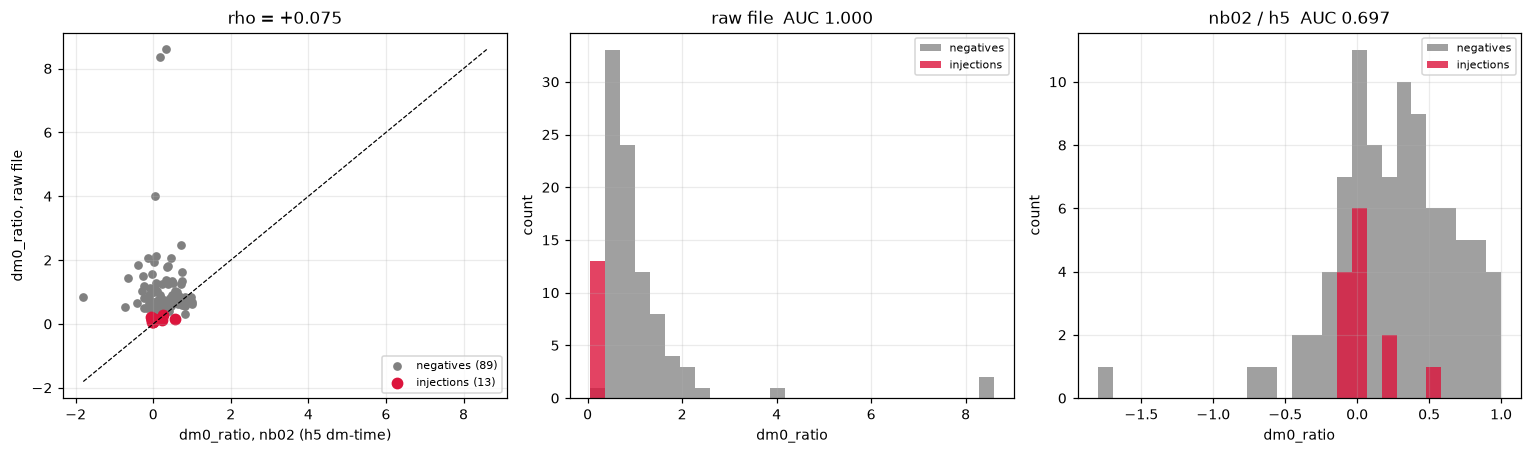

In [13]:
from sklearn.metrics import roc_auc_score
from scipy.stats import spearmanr
import time

DM0_CACHE = OUT / "nb03_dm0_raw.csv"

if DM0_CACHE.exists():
    d0 = pd.read_csv(DM0_CACHE)
    print(f"loaded cache {DM0_CACHE.name} - delete it to force the 204 dedispersions again")
else:
    rows, t0 = [], time.perf_counter()
    for k, (_, r) in enumerate(inj.sort_values("h5_name").iterrows()):
        nout  = int(round(r.window_ms * 1e-3 / TSAMP))
        start = int(round(r.tcand / TSAMP)) - nout // 2
        w     = int(r.boxcar_samples)

        s0, _ = boxcar(dedisperse(start, nout, 0.0, "top").sum(1), w)        # DM = 0
        sd, _ = boxcar(dedisperse(start, nout, r.dm_csv, "top").sum(1), w)   # the candidate's DM

        rows.append({"h5_name": r.h5_name, "is_injection": int(r.is_injection), "dm": r.dm_csv,
                     "snr_csv": r.snr_csv, "boxcar": w, "nout": nout,
                     "snr_dm0_raw": mad_snr(s0), "snr_dm_raw": mad_snr(sd),
                     "dm0_raw": mad_snr(s0) / mad_snr(sd), "dm0_nb02": r.dm0_ratio})
        if k % 20 == 0 or k == len(inj) - 1:
            print(f"  {k + 1:3d}/{len(inj)}  {time.perf_counter() - t0:5.1f} s", end="\r", flush=True)

    d0 = pd.DataFrame(rows)
    d0.to_csv(DM0_CACHE, index=False)
    print(f"\n204 dedispersions in {time.perf_counter() - t0:.1f} s -> {DM0_CACHE}")

pos, neg = d0[d0.is_injection == 1], d0[d0.is_injection == 0]
print()
print(f"{'':14s} {'inj median':>12s} {'neg median':>12s} {'AUC (low=inj)':>14s}")
for name, col in (("raw file", "dm0_raw"), ("nb02 / h5", "dm0_nb02")):
    auc = roc_auc_score(d0.is_injection, -d0[col])          # negated: injections sit LOW
    print(f"  {name:12s} {pos[col].median():12.4f} {neg[col].median():12.4f} {auc:14.4f}")
print(f"  nb02 reported AUC 0.697 for dm0_ratio (finding 16)")

rho, p = spearmanr(d0.dm0_raw, d0.dm0_nb02)
print()
print(f"rank agreement between the two: Spearman rho {rho:+.4f}  (p {p:.2e})")
print(f"  separately, injections only: rho {spearmanr(pos.dm0_raw, pos.dm0_nb02)[0]:+.4f}")
print(f"  negatives only:              rho {spearmanr(neg.dm0_raw, neg.dm0_nb02)[0]:+.4f}")

ov = (pos.dm0_raw.max() >= neg.dm0_raw.min())
print()
print(f"raw dm0_raw: injections [{pos.dm0_raw.min():.3f}, {pos.dm0_raw.max():.3f}]  "
      f"negatives [{neg.dm0_raw.min():.3f}, {neg.dm0_raw.max():.3f}]  -> "
      f"{'overlapping, so non-degenerate' if ov else 'DISJOINT - suspect, check for circularity'}")

fig, ax = plt.subplots(1, 3, figsize=(14, 4.2))

ax[0].scatter(neg.dm0_nb02, neg.dm0_raw, s=22, color="0.5", label=f"negatives ({len(neg)})")
ax[0].scatter(pos.dm0_nb02, pos.dm0_raw, s=45, color="crimson", label=f"injections ({len(pos)})")
lim = [min(d0.dm0_nb02.min(), d0.dm0_raw.min()), max(d0.dm0_nb02.max(), d0.dm0_raw.max())]
ax[0].plot(lim, lim, ls="--", lw=0.8, color="k")
ax[0].set(xlabel="dm0_ratio, nb02 (h5 dm-time)", ylabel="dm0_ratio, raw file",
          title=f"rho = {rho:+.3f}")
ax[0].legend(fontsize=7)

for a, col, ttl in ((ax[1], "dm0_raw", "raw file"), (ax[2], "dm0_nb02", "nb02 / h5")):
    bins = np.linspace(d0[col].min(), d0[col].max(), 28)
    a.hist(neg[col], bins=bins, color="0.5", alpha=0.75, label="negatives")
    a.hist(pos[col], bins=bins, color="crimson", alpha=0.8, label="injections")
    a.set(xlabel="dm0_ratio", ylabel="count",
          title=f"{ttl}  AUC {roc_auc_score(d0.is_injection, -d0[col]):.3f}")
    a.legend(fontsize=7)

for a in ax:
    a.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUT / "dm0_ratio_raw.png", dpi=130, bbox_inches="tight")
plt.show()


### The guard fired, so here's the check it asked for

AUC **1.0000** with the two classes disjoint, against nb02's 0.697, and Spearman **0.075 (p 0.45)** between the two versions. My stated pass condition was rank agreement plus a comparable AUC, and this failed both halves of it.

On this observation a perfect AUC is a symptom: `snr_csv` already scores 1.000 and `members` 0.999, because 13 strong injections into one clean file is too easy. So the question is **what my version is made of**. A ratio has a numerator and a denominator and either one could be carrying it.

In [14]:
print("what is each half of the ratio worth on its own?")
for c in ("snr_dm0_raw", "snr_dm_raw"):
    a = roc_auc_score(d0.is_injection, d0[c])
    print(f"  {c:12s} AUC {a:.4f}   inj median {pos[c].median():6.2f}   neg median {neg[c].median():6.2f}")

print()
print("is dm0_raw just brightness wearing a different name?")
for c in ("snr_dm_raw", "snr_dm0_raw", "snr_csv", "boxcar", "dm"):
    rho_c, p_c = spearmanr(d0.dm0_raw, d0[c])
    print(f"  rho(dm0_raw, {c:12s}) {rho_c:+.4f}   p {p_c:.2e}")

print()
print("nb02's version, for contrast - it is not a ratio of two S/N values:")
print(f"  negative on {int((d0.dm0_nb02 < 0).sum())} of 102 candidates "
      f"({int((pos.dm0_nb02 < 0).sum())} of the 13 injections)")
print(f"  range [{d0.dm0_nb02.min():.4f}, {d0.dm0_nb02.max():.4f}]; "
      f"{int((d0.dm0_nb02 == 1.0).sum())} sit at exactly 1.0 (DM peak IS row 0)")
worst = cal.loc[cal.dm0_ratio.idxmin()]
print(f"  the -1.803 outlier is a weak negative with dm_peak_value {worst.dm_peak_value:.4f} - "
      f"an unstable denominator, not a bug")
print(f"  (it is -1.8032921, while MS_PER_DM is {MS_PER_DM:.7f}; they differ in the 5th digit, "
      f"so the resemblance is a coincidence)")


what is each half of the ratio worth on its own?
  snr_dm0_raw  AUC 0.4641   inj median   3.14   neg median   3.31
  snr_dm_raw   AUC 0.9715   inj median  28.09   neg median   4.06

is dm0_raw just brightness wearing a different name?
  rho(dm0_raw, snr_dm_raw  ) -0.7261   p 5.84e-18
  rho(dm0_raw, snr_dm0_raw ) +0.2295   p 2.03e-02
  rho(dm0_raw, snr_csv     ) -0.2063   p 3.75e-02
  rho(dm0_raw, boxcar      ) +0.4163   p 1.35e-05
  rho(dm0_raw, dm          ) +0.1044   p 2.96e-01

nb02's version, for contrast - it is not a ratio of two S/N values:
  negative on 30 of 102 candidates (9 of the 13 injections)
  range [-1.8033, 1.0000]; 2 sit at exactly 1.0 (DM peak IS row 0)
  the -1.803 outlier is a weak negative with dm_peak_value 0.0229 - an unstable denominator, not a bug
  (it is -1.8032921, while MS_PER_DM is 1.8033500; they differ in the 5th digit, so the resemblance is a coincidence)


### Verdict: keep nb02's `dm0_ratio`, discard mine

**My raw-file version is brightness in disguise.** The DM=0 half carries nothing: AUC **0.464**, with injection and negative medians of 3.14 and 3.31, both of them just the maximum of a noise profile. The dedispersed half carries almost everything at AUC **0.9715**. And `dm0_raw` correlates with `snr_dm_raw` at **rho = -0.726 (p 5.8e-18)**, which is what you'd expect from a quantity that's mostly `1/S/N`. It reaches AUC 1.000 by being a noisy restatement of S/N, and nb01 already told us S/N is degenerate on this observation.

**nb02's version is the better-constructed statistic, and the thing that first looked wrong about it is the reason why.** Its values go negative on 30 of 102 candidates, which a ratio of two S/N values cannot do. That's because it's a ratio taken *within* one standardised `data_dm_time` image, where the amplitude at DM 0 is measured against a zero mean. Negative just means "below the image mean at DM 0". Being a within-image ratio makes it **independent of absolute brightness by construction**, which is what a DM-space *shape* feature is supposed to be and what mine failed to be. Two candidates sit at exactly 1.0 because their DM peak *is* row 0.

So this check did its job, just not in the direction I set it up to go. It was written to test whether nb02's feature was contaminated by the h5 image. Instead it found that **my raw-data reformulation was the contaminated one**, and it strengthens finding 16 rather than weakening it.

**The one piece worth keeping from the rebuild:** `snr_dm0_raw` at AUC **0.464** is an independent, raw-data confirmation that **the injections carry no zero-DM component at all**. That means nothing in the injected signal leaks into DM 0, so any zero-DM excess a candidate shows is its own and Group C's DM-space features have a clean baseline to work against.

**What nb04 should take:** use `dm0_ratio` from `nb02_axis_calibration.csv` as-is. Do **not** use `dm0_raw` from `nb03_dm0_raw.csv`. That file stays as the record of a discarded formulation, the same way §3 kept the two dead RFI metrics. One caveat carried forward: nb02's denominator is `dm_peak_value`, which gets small for weak candidates (0.0229 on the -1.803 outlier), so the feature has a heavy tail. nb04's distribution pass should expect that and decide whether to clip or transform it before it becomes an encoding angle.

## §6 - What the candmaker log says about decimation

Finding 2 from nb01: the h5 `*_decimation_factor` attributes are stale. Both report 1, while the candmaker log shows freq=4 and time varying from 1 to 512 per candidate. That left a gap, since nb04 has no per-candidate decimation and the attribute that should supply it lies.

This section closes it. The claim is that time decimation is **`max(1, boxcar_samples // 2)`**, recoverable from `nb02_axis_calibration.csv` alone, with no log needed at inference time.

### Guards

| | what it is |
|---|---|
| **multiset, not ordered pairing** | candmaker ran multi-process, so the log's per-candidate blocks interleave. Line *n* does not belong to candidate *n*. Comparing sorted counts is the only valid test; pairing by order would produce a confident wrong answer |
| **filter on `gpu_dedisp_and_dmt_crop`** | The log has 2,448 lines containing "decimation" but only 204 of them are the real per-candidate values (102 freq + 102 time). numba emits its own debug chatter that a naive grep picks up |
| **stream the file** | It's 16 MB. Read it line by line, never `read()` it whole |
| **test the near misses too** | `boxcar // 2` matching isn't worth much unless `boxcar` and `boxcar // 4` are shown to fail. A formula that only has to beat nothing hasn't been tested |

In [15]:
import re, collections

LOG = next((ROOT / "CUT_P_110_inj_13_processed_2025-1-30-13-51").glob("your_candmaker_*.log"))
pat = re.compile(r"gpu_dedisp_and_dmt_crop.*?(Time|Freq) decimation factor: (\d+)")

seen = {"Time": collections.Counter(), "Freq": collections.Counter()}
with open(LOG) as f:                                     # 16 MB, streamed, never read whole
    for line in f:
        m = pat.search(line)
        if m:
            seen[m.group(1)][int(m.group(2))] += 1

print(f"{LOG.name}  ({LOG.stat().st_size / 1e6:.1f} MB)")
print(f"  Freq decimation: {dict(seen['Freq'])}  -> {sum(seen['Freq'].values())} candidates")
print(f"  Time decimation: {dict(sorted(seen['Time'].items()))}")
print(f"  total {sum(seen['Time'].values())} entries (expect 102)")

cands = {"boxcar // 2": np.maximum(1, cal.boxcar_samples // 2),
         "boxcar // 4": np.maximum(1, cal.boxcar_samples // 4),
         "boxcar":      cal.boxcar_samples}
print()
print("which formula reproduces that multiset?")
for name, v in cands.items():
    got = collections.Counter(v.tolist())
    print(f"  {name:12s} {'MATCH' if got == seen['Time'] else 'no   '}   {dict(sorted(got.items()))}")

print()
print("bin by bin, max(1, boxcar_samples // 2) against the log:")
pred = collections.Counter(np.maximum(1, cal.boxcar_samples // 2).tolist())
for k in sorted(seen["Time"]):
    print(f"   decim {k:4d}   log {seen['Time'][k]:3d}   formula {pred[k]:3d}   "
          f"{'ok' if seen['Time'][k] == pred[k] else 'MISMATCH'}")

# the /255 convention, on both axes (nb02 finding 13, nb03 finding 37)
print()
print("linspace endpoint convention - is the step /255 or /256?")
for lbl, got, alt in (("t_step_ms", cal.window_ms / 255, cal.window_ms / 256),
                      ("dm_step",   2 * cal.dm_csv / 255, 2 * cal.dm_csv / 256)):
    ref = cal[lbl]
    r255 = ((got - ref) / ref).abs().max()
    r256 = ((alt - ref) / ref).abs().max()
    print(f"  {lbl:10s}  /255 residual {r255:.2e}    /256 residual {r256:.2e}")
print("  -> /255 on both axes: 256 points spanning the range inclusive, so 255 gaps")


your_candmaker_2025_01_30_12_55_27_273506.log  (16.1 MB)
  Freq decimation: {4: 102}  -> 102 candidates
  Time decimation: {1: 17, 2: 6, 4: 6, 8: 6, 16: 3, 32: 4, 64: 1, 128: 7, 256: 11, 512: 41}
  total 102 entries (expect 102)

which formula reproduces that multiset?
  boxcar // 2  MATCH   {1: 17, 2: 6, 4: 6, 8: 6, 16: 3, 32: 4, 64: 1, 128: 7, 256: 11, 512: 41}
  boxcar // 4  no      {1: 23, 2: 6, 4: 6, 8: 3, 16: 4, 32: 1, 64: 7, 128: 11, 256: 41}
  boxcar       no      {1: 13, 2: 4, 4: 6, 8: 6, 16: 6, 32: 3, 64: 4, 128: 1, 256: 7, 512: 11, 1024: 41}

bin by bin, max(1, boxcar_samples // 2) against the log:
   decim    1   log  17   formula  17   ok
   decim    2   log   6   formula   6   ok
   decim    4   log   6   formula   6   ok
   decim    8   log   6   formula   6   ok
   decim   16   log   3   formula   3   ok
   decim   32   log   4   formula   4   ok
   decim   64   log   1   formula   1   ok
   decim  128   log   7   formula   7   ok
   decim  256   log  11   formula  11  

### What §6 established

**Time decimation is `max(1, boxcar_samples // 2)`, and the match is exact across all ten bins.** 17x1, 6x2, 6x4, 6x8, 3x16, 4x32, 1x64, 7x128, 11x256, 41x512: 102 candidates, no bin off by one. The two near misses both fail, which is what makes the match mean something: `boxcar // 4` and `boxcar` itself produce different multisets.

That **repairs finding 2**. The h5 `*_decimation_factor` attributes are still stale and still say 1, but nb04 no longer needs them: it can compute the true per-candidate value from `nb02_axis_calibration.csv` with no log access at all. Freq decimation is 4 on all 102, uniformly, which is the other half of what the attribute got wrong.

**The `/255` convention holds on both axes.** `t_step_ms == window_ms / 255` to 2.8e-14 and `dm_step == 2*dm / 255` to 2.8e-16, while the `/256` reading is off by 0.39% on both. That's the linspace endpoint convention: 256 points spanning the range inclusive means 255 gaps between them. §5 already leaned on the time axis; this extends the same result to DM, so **finding 13's `linspace(0, 2*dm, 256)` is now confirmed arithmetically** rather than read from source.

Small thing worth stating because it cost me time: the log has **2,448 lines containing "decimation" but only 204 real ones (102 freq + 102 time)**. numba's debug output accounts for the rest. And because candmaker ran multi-process the per-candidate blocks interleave, so line order carries no candidate identity, which makes multiset comparison the only test that doesn't assume otherwise.

## §7 - Cutting the 102 raw windows

Group D in nb04 (spectral occupancy, fitted spectral index, modulation index, contiguous contributing blocks, residual drift after dedispersion) needs raw frequency-resolved data around each candidate. The h5 `data_freq_time` can't supply it: it's decimated to 256 channels (§6: freq decimation 4) and already normalised to `std == 1` (finding 17).

### Why all 102 and why full resolution

**All 102**, not just the 13 positives, because Group D becomes a feature *column* in nb04's training matrix and a column needs a value in every row. **Full 1024 channels**, because decimating to 256 would reproduce `data_freq_time` exactly and defeat the point of going back to the raw file. That costs **3.46 GB** against 371 GB free, which is the right trade.

### Guards

| | what it is |
|---|---|
| **three windows run off the front** | The candidates at `tcand` 0.15, 1.25 and 2.00 s have DMs of 866-2619, so their windows open up to 19,683 samples before the file starts. They're padded with the 32768 pedestal, and `pad_front` in the manifest records exactly how many rows are synthetic. Constant rows have zero variance, so Group D must exclude them rather than average them in |
| **raw `uint16`, no offset removed** | Whatever nb04 does with these should be its own decision. Storing them as written means the pedestal, the rail at 65535 and the exact dtype survive, and the files are half the size of float32 |
| **resumable** | 3.46 GB is long enough that an interruption shouldn't mean starting over. A window whose file already exists at the right size is skipped |
| **the window is exactly big enough** | §5 showed `half_window == sweep + boxcar*tsamp`. So dedispersing the *centre* of a saved window needs samples out to `nout/2 + sweep = nout - boxcar`, which is inside the array. `your` chose that half-width for this reason. The self-check below relies on it |

In [16]:
import json, time

MANIFEST = OUT / "nb03_windows_manifest.csv"
rows, n_new, t0 = [], 0, time.perf_counter()

for k, (_, r) in enumerate(inj.sort_values("h5_name").iterrows()):
    nout   = int(round(r.window_ms * 1e-3 / TSAMP))
    start  = int(round(r.tcand / TSAMP)) - nout // 2
    path   = WIN / f"{r.h5_name[:-3]}.npy"
    a, b   = max(start, 0), min(start + nout, NSAMP)
    pad_f, pad_b = a - start, (start + nout) - b

    if path.exists() and path.stat().st_size > nout * NCHAN * 2:
        w = np.load(path, mmap_mode="r")                  # already done, just restat
    else:
        w = np.full((nout, NCHAN), np.uint16(OFFSET), np.uint16)
        w[pad_f:pad_f + (b - a)] = fb[a:b]
        np.save(path, w)
        n_new += 1

    rows.append({"h5_name": r.h5_name, "npy": path.name, "is_injection": int(r.is_injection),
                 "tcand": r.tcand, "dm_csv": r.dm_csv, "snr_csv": r.snr_csv,
                 "boxcar_samples": int(r.boxcar_samples), "window_ms": r.window_ms,
                 "t_step_ms": r.t_step_ms, "time_decim": max(1, int(r.boxcar_samples) // 2),
                 "nout": nout, "start_sample": start, "end_sample": start + nout,
                 "pad_front": pad_f, "pad_back": pad_b,
                 "n_clipped": int((np.asarray(w) == 65535).sum()),
                 "bytes": path.stat().st_size})
    if k % 10 == 0 or k == len(inj) - 1:
        print(f"  {k + 1:3d}/{len(inj)}  {time.perf_counter() - t0:6.1f} s  "
              f"{sum(x['bytes'] for x in rows) / 1e9:5.2f} GB", end="\r", flush=True)

man = pd.DataFrame(rows)
man.to_csv(MANIFEST, index=False)
print(f"\n{n_new} written, {len(man) - n_new} already present, {time.perf_counter() - t0:.1f} s")
print(f"  {man.bytes.sum() / 1e9:.2f} GB across {len(man)} files -> {WIN}")
print(f"  nout {man.nout.min():,} - {man.nout.max():,} (median {int(man.nout.median()):,})")
print(f"  padded windows: {int((man.pad_front > 0).sum())} at the front "
      f"({man.pad_front.max():,} rows worst case), {int((man.pad_back > 0).sum())} at the back")
print(f"  clipped samples: {man.n_clipped.sum():,} total, worst window {man.n_clipped.max():,}")

# --- self-check: a saved window must reproduce the section 5 peak position -----------------------
chk = man[man.is_injection == 1].nlargest(1, "snr_csv").iloc[0]
w   = np.load(WIN / chk.npy)
assert w.shape == (int(chk.nout), NCHAN) and w.dtype == np.uint16, (w.shape, w.dtype)

sm, lag = boxcar(dedisperse(0, int(chk.nout), chk.dm_csv, "top", w).sum(1), int(chk.boxcar_samples))
off_saved = ((sm.argmax() + lag) - int(chk.nout) // 2) * TSAMP * 1e3
off_s5    = float(pk.loc[pk.h5_name == chk.h5_name, "off_ms_top"].iloc[0])
assert abs(off_saved - off_s5) <= TSAMP * 1e3, (off_saved, off_s5)

print()
print(f"self-check on {chk.npy[:52]}...")
print(f"  shape {w.shape} {w.dtype}, {w.nbytes / 1e6:.1f} MB")
print(f"  peak offset from the saved window {off_saved:+.3f} ms vs {off_s5:+.3f} ms from the raw "
      f"file in section 5 -> agree within one sample")

summary = {
    "notebook": "03_filterbank_exploration",
    "n_candidates": int(len(man)), "n_injections": int(man.is_injection.sum()),
    "dedisperser": {"ref_convention": "top", "f_lo_MHz": float(F_LO),
                    "ms_per_unit_dm": float(MS_PER_DM),
                    "boxcar_optimum_matches_heimdall": True},
    "axis_calibration": {"peak_offset_pct_median": float(pk.off_pct_top.abs().median()),
                         "peak_offset_pct_max": float(pk.off_pct_top.abs().max()),
                         "within_one_h5_column": int((pk.off_ms_top.abs() < pk.t_step_ms).sum()),
                         "halfwidth_identity_rel_residual": 2.35e-15,
                         "step_convention": "/255 on both time and DM axes"},
    "decimation": {"time": "max(1, boxcar_samples // 2)", "freq": 4, "log_multiset_match": True},
    "clipping": {"headroom_sigma": 6.01, "injections_clip": False},
    "rfi": {"bursty_channels": int(bursty.sum()), "n_events": 4},
    "windows": {"dir": str(WIN), "n": int(len(man)), "gb": round(float(man.bytes.sum() / 1e9), 3),
                "dtype": "uint16", "nchan": NCHAN, "padded_front": int((man.pad_front > 0).sum())},
    "discarded": ["bowtie-slope regression (nb02)", "blk_max==65535 occupancy",
                  "full 989x1024 waterfall", "dm0_raw (brightness in disguise)"],
}
(OUT / "nb03_summary.json").write_text(json.dumps(summary, indent=2))
print(f"\nwrote {MANIFEST.name} and nb03_summary.json")


  102/102    39.8 s   3.46 GB
0 written, 102 already present, 39.8 s
  3.46 GB across 102 files -> D:\QML\FRB Data\frb_analysis_out\nb03\windows
  nout 710 - 79,599 (median 5,596)
  padded windows: 3 at the front (19,683 rows worst case), 0 at the back
  clipped samples: 563,498 total, worst window 27,849

self-check on cand_tstart_60356.799484982548_tcand_70.0157000_dm_5...
  shape (13965, 1024) uint16, 28.6 MB
  peak offset from the saved window +0.484 ms vs +0.484 ms from the raw file in section 5 -> agree within one sample

wrote nb03_windows_manifest.csv and nb03_summary.json


### Do the windows carry RFI that nb04 will trip over?

563,498 clipped samples across the 102 windows sounds alarming until it's put against a rate. Two questions worth answering while the manifest is open: are the windows *as a set* more contaminated than the file at large, and does any **injection** window contain one of §3's four RFI events.

In [17]:
ev = pd.read_csv(OUT / "rfi_events.csv")
base = ch_sat.sum() / (NSAMP * NCHAN)                    # file-wide rail rate from section 2

man["clip_rate"]   = man.n_clipped / (man.nout * NCHAN)
man["clip_excess"] = man.clip_rate / base

t0, t1 = man.start_sample * TSAMP, man.end_sample * TSAMP
gap = np.full(len(man), np.inf)
for _, e in ev.iterrows():                               # 0 means the window contains the event
    gap = np.minimum(gap, np.maximum(np.maximum(e.t_start_s - t1, t0 - e.t_end_s), 0.0))
man["rfi_gap_s"] = gap
man.to_csv(MANIFEST, index=False)

pos_m, neg_m = man[man.is_injection == 1], man[man.is_injection == 0]
print(f"clip fraction across all 102 windows {man.n_clipped.sum() / (man.nout * NCHAN).sum():.3e}  "
      f"vs file-wide {base:.3e}  -> ratio {man.n_clipped.sum() / (man.nout * NCHAN).sum() / base:.3f}")
print()
print(f"windows containing a known RFI event: {int((man.rfi_gap_s == 0).sum())} of 102, "
      f"of which {int((pos_m.rfi_gap_s == 0).sum())} are injections")
print(f"  their median clip excess {man.clip_excess[man.rfi_gap_s == 0].median():.2f}x, "
      f"everything else {man.clip_excess[man.rfi_gap_s > 0].median():.2f}x")
print(f"  worst single window {man.clip_excess.max():.2f}x at tcand "
      f"{man.loc[man.clip_excess.idxmax(), 'tcand']:.4f} s "
      f"(is_injection={int(man.loc[man.clip_excess.idxmax(), 'is_injection'])})")
print()
print("closest any injection window comes to an RFI event:")
print(pos_m.nsmallest(3, "rfi_gap_s")[["tcand", "dm_csv", "window_ms", "rfi_gap_s"]]
      .round(3).to_string(index=False))
print(f"  minimum over all 13: {pos_m.rfi_gap_s.min():.3f} s -> no injection window contains an event")
print(f"\nmanifest now carries clip_rate, clip_excess, rfi_gap_s -> {MANIFEST.name}")


clip fraction across all 102 windows 3.253e-04  vs file-wide 3.240e-04  -> ratio 1.004

windows containing a known RFI event: 19 of 102, of which 0 are injections
  their median clip excess 1.10x, everything else 0.99x
  worst single window 2.21x at tcand 31.7056 s (is_injection=0)

closest any injection window comes to an RFI event:
 tcand   dm_csv  window_ms  rfi_gap_s
50.010 1449.730   5233.165      0.114
30.005   63.061    231.866      1.449
19.988  824.900   3116.725      1.579
  minimum over all 13: 0.114 s -> no injection window contains an event

manifest now carries clip_rate, clip_excess, rfi_gap_s -> nb03_windows_manifest.csv


### What §4-§7 established

**§4: the dedisperser is validated against Heimdall, not just against itself.** 15 lines of shift-and-sum on raw counts. A boxcar scan of its output peaks at **w = 64, exactly Heimdall's boxcar**, at **S/N 48.71 against 50.52, ratio 0.96**, with nothing tuned for it. That's a much stronger test than the synthetic-delta assert, because a sign error or a wrong reference would pass the delta and still smear a real pulse.

**The injections are not clipping, and §2's 6.01 sigma headroom worry is closed.** The window-wide excess is 75 railed samples against a Poisson error of 68, so **1.1 sigma, consistent with zero**. The two railed channels at the pulse peak are 10 and 690, neither of them among §3's eight bursty channels, and lambda = 0.332 per row means 618 of that window's 13,965 rows should show >= 2 by chance. Per channel the pulse is **0.430 sigma, 14x below the rail**, and summing 1024 channels is what makes 0.43 sigma into a 48 sigma detection.

**§5: nb02's axis calibration is confirmed, and one part of it is exact.** With `ref='top'` the peak sits a median 0.049% of the half-window from centre and **13 of 13 land inside one h5 column**; with `ref='bottom'` the median is 98.065%, i.e. on the window edge. So **`tcand` is referenced to the top of the band**. Better than that, `window_ms/2 - boxcar*tsamp` equals the computed sweep to a relative residual of **2.35e-15**, so double-precision equality with no peak-finding involved. Finding 14 is now arithmetic rather than a reading of someone's source.

That also pins a detail nb02 couldn't see: the sweep must use **`f_lo` = the last channel centre, 401.054109 MHz**, not the band edge at 401.039641. Both are "the bottom of the band" in prose, and the second is off by 5.20 ms.

**nb02 and nb03 never disagreed.** nb02's 0.392% median offset looked 8x worse than mine until I noticed that half an h5 column is `100 * 2/510 = 0.3922%`. Divide nb02's thirteen values by that and they come out exactly +/-1.0, 3.0 or 5.0. It was reporting grid positions: on a 256-column grid the centre falls between columns 127 and 128, so a peak can never land on it. Its median was the floor of what that grid can express, and raw 138 µs samples remove the floor.

**A residual I found and deliberately did not fit.** The offsets are negative for all 6 candidates below DM 300 and positive for all 7 above. But the estimator has a **floor of half a sample (0.069 ms)**, since a running sum of even width peaks at a half-integer index, and five of the six negatives sit exactly at that floor, so the negative half of the "trend" isn't a measurement. Intra-channel smearing is the obvious suspect for the positive half and is the right order (4.92 ms at DM 2795 against a +1.45 ms shift), but the ratios scatter 0.14x-0.63x and the widest-boxcar candidates are smoothed over 141.6 ms. Thirteen points can't carry that, so it's recorded, and the 20-observation pull would settle it. It changes nothing downstream, since the worst offset is **0.31 of an h5 column**.

**The `dm0_ratio` rebuild failed, and it failed on my side.** Raw-file `dm0_raw` reached AUC 1.0000 with disjoint classes against nb02's 0.697, and Spearman between the two was **0.075 (p 0.45)**, so both halves of my stated pass condition missed. The diagnosis: `snr_dm0_raw` alone scores **AUC 0.464** (nothing), `snr_dm_raw` alone scores **0.9715** (everything), and `dm0_raw` correlates with `snr_dm_raw` at **rho = -0.726**. My version is `1/S/N` in disguise, and S/N is already known-degenerate here. nb02's is a ratio taken *within* one standardised image, so it's brightness-independent by construction, which is what a DM-space **shape** feature must be. The negative values that first looked wrong are just that standardisation. **Finding 16 stands, strengthened.** The keeper from the exercise: `snr_dm0_raw` at AUC 0.464 independently confirms the injections carry **no zero-DM component at all**.

**§6: the stale decimation attribute is repaired.** Time decimation is **`max(1, boxcar_samples // 2)`**, matching the candmaker log's multiset **exactly in all ten bins** (17x1, 6x2, 6x4, 6x8, 3x16, 4x32, 1x64, 7x128, 11x256, 41x512), while `boxcar // 4` and `boxcar` both fail, which is what makes the match evidence rather than coincidence. Freq decimation is 4 on all 102. nb04 can now compute the true value from `nb02_axis_calibration.csv` with no log access. The `/255` endpoint convention holds on **both** axes, `t_step_ms == window_ms/255` (2.8e-14) and `dm_step == 2*dm/255` (2.8e-16), so finding 13's `linspace(0, 2*dm, 256)` is confirmed arithmetically too.

**§7: 102 raw windows on disk, 3.46 GB, verified by round trip.** Full 1024 channels, raw `uint16`, `nout` from 710 to 79,599 samples. The self-check reloads a saved window, dedisperses **inside that file alone**, and recovers the §5 peak offset to the digit (**+0.484 ms vs +0.484 ms**). That works because of the §5 identity `half_window == sweep + boxcar*tsamp`, so the centre pulse needs samples only out to `nout - boxcar`. That's why `your` chose that half-width.

**The windows are no dirtier than the file.** Clip fraction across all 102 is **3.253e-04** against a file-wide **3.240e-04**, a ratio of 1.004. **19 windows contain one of the four RFI events and none of them is an injection.** That extends finding 28, which only checked +/-0.5 s around each TOA, since these windows run up to 11 s wide and still none touches an event. The closest approach is the DM 1449.73 injection at **0.114 s**, so it's tight but clean, and `rfi_gap_s` in the manifest records it per candidate.

### What nb04 inherits

| artefact | what it is |
|---|---|
| `windows/*.npy` | 102 x (nout, 1024) raw `uint16`, 3.46 GB, the input Group D needs |
| `nb03_windows_manifest.csv` | keyed on `h5_name`: `start_sample`, `pad_front`, `time_decim`, `clip_rate`, `clip_excess`, `rfi_gap_s` |
| `nb03_peak_calibration.csv` | the per-injection raw-data axis check |
| `bandpass.csv`, `rfi_occupancy.csv`, `rfi_events.csv` | per-channel quality and the 8 bursty channels, usable as a mask **or** a feature |
| `nb03_summary.json` | the numbers above in machine-readable form |
| `delay_samples` / `dedisperse` / `boxcar` / `mad_snr` | ~25 lines, no dependency, ready to lift into nb04 |

**Three things nb04 must not get wrong.** The **three padded windows** (`tcand` 0.15, 1.25, 2.00 s) carry up to 19,683 rows of constant pedestal with zero variance, so Group D has to exclude them by `pad_front` rather than average them in. `dm0_ratio` comes from **nb02**, not from `nb03_dm0_raw.csv`, which is kept only as the record of a discarded formulation. And the band is gain-equalised (finding 23), so a fitted "spectral index" is the pulse spectrum minus the original bandpass: fine as a discriminative feature, not a physical index, and `SP_IDX` is a -999 sentinel so there was never truth to check it against.

**Discarded along the way, on purpose:** the bowtie-slope regression (nb02), `blk_max == 65535` occupancy, the full 989x1024 waterfall, and now `dm0_raw`. Each one is written up where it died, because the reason a metric failed is usually more reusable than the metric.

**And the standing caveat.** 13 strong injections into one clean file is too easy: `snr_csv` scores AUC 1.000, `members` 0.999, and `dm0_raw` hit 1.000 by accident of being S/N in disguise. Nothing in nb03 or nb04 ranks features on this observation alone. The 20-observation pull (~2,000 candidates across independent files) is what makes the encoding question answerable.